# Portfolio Risk Engine — Yahoo Finance

**MSc FBD · Portfolio Risk Management with Python · NEOMA Business School — projet final**

Moteur de risque interactif construit sur des données Yahoo Finance (`yfinance`). Le notebook :

1. **demande les paramètres** : tickers, classes d'actifs, poids, valeur, devise, période, niveaux de confiance, horizon, fenêtre, nombre de simulations ;
2. **télécharge et prépare les données** : cours ajustés, conversion de devise, alignement des calendriers, sauvegarde en CSV ;
3. calcule **rendement, volatilité, Sharpe, drawdown, bêta, matrice de corrélation** ;
4. calcule la **VaR historique, paramétrique et Monte Carlo** et l'**Expected Shortfall** (95/99 %, 1 jour et *h* jours), ainsi que la **contribution au risque par actif** ;
5. fait un **backtest glissant** : exceptions, test de Kupiec, feux tricolores de Bâle ;
6. lance le **module de stress** : épisodes historiques, chocs hypothétiques, stress de corrélation et de volatilité, stress inverse. Chaque perte est comparée à la VaR et à l'ES ;
7. ajoute des **analyses complémentaires** (corrélations de crise, concentration) et un **résumé automatique** des réponses aux 8 questions du cours.

**Utilisation** : *Run All*. À chaque question, appuyez sur **Entrée** pour garder la valeur par défaut, ou tapez la vôtre.
Si une saisie est invalide, un message explique le problème et la question est reposée.
Avec `INTERACTIVE = False`, le notebook utilise les valeurs par défaut sans rien demander (exécution reproductible).

> Hypothèses générales : rendements simples pour le P&L du portefeuille (poids constants, rééquilibrage quotidien), rendements log pour les statistiques annualisées (comme dans le cours), 252 jours de bourse par an, VaR et ES exprimées comme des pertes positives.

## 0. Configuration

In [1]:
import json
import re
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from scipy.special import xlogy
import yfinance as yf
from IPython.display import display, Markdown

try:
    from IPython.core.error import StdinNotImplementedError
except ImportError:  # hors Jupyter
    class StdinNotImplementedError(Exception):
        pass

warnings.filterwarnings("ignore", category=FutureWarning)

INTERACTIVE = True      # False : toutes les valeurs par défaut sont utilisées sans question
STRICT = True           # True : les règles du projet (≥ 6 tickers, ≥ 3 classes, ≥ 5 ans) sont bloquantes
SEED = 42               # graine fixe -> résultats Monte Carlo reproductibles
TRADING_DAYS = 252

DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

# Palette des graphiques (couleurs catégorielles dans un ordre fixe ; rouge réservé aux exceptions/pertes extrêmes)
C1, C2, C3, C4 = "#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7"
C_TAIL, C_BODY = "#d03b3b", "#9ec5f4"
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK, "font.size": 10,
    "lines.linewidth": 2, "legend.frameon": False, "figure.dpi": 110,
})
DIVERGING = LinearSegmentedColormap.from_list("div", ["#1c5cab", "#f0efec", "#e34948"])

print(f"yfinance {yf.__version__} · pandas {pd.__version__} · numpy {np.__version__} · seed = {SEED}")

yfinance 1.2.0 · pandas 3.0.2 · numpy 2.4.4 · seed = 42


## 1. Saisie interactive des paramètres

In [2]:
class InputError(ValueError):
    """Erreur de saisie : le message est affiché tel quel à l'utilisateur."""


def ask(prompt, default, parser=str, validator=None):
    """Pose une question. Entrée vide -> valeur par défaut. Saisie invalide -> message clair et nouvelle question."""
    shown = str(default)
    while True:
        raw = ""
        if INTERACTIVE:
            try:
                raw = input(f"{prompt} [défaut : {shown}] → ").strip()
            except (EOFError, StdinNotImplementedError):
                raw = ""  # pas de clavier disponible (ex. nbconvert) -> valeur par défaut
        text = raw or shown
        try:
            value = parser(text)
            if validator is not None:
                validator(value)
            return value
        except (ValueError, InputError) as exc:
            print(f"   ✗ {prompt} : {exc}")
            if not INTERACTIVE or not raw:
                raise InputError(f"Valeur invalide pour « {prompt} » : {exc}") from exc
            print("     Merci de corriger la saisie.")


def project_rule(ok, message):
    """Règle du projet : bloquante si STRICT, sinon simple avertissement."""
    if ok:
        return
    if STRICT:
        raise InputError(message + " (règle du projet ; mettre STRICT = False pour l'ignorer)")
    print(f"   ⚠ {message}")


def parse_tickers(s):
    items = [x.strip().upper() for x in re.split(r"[,;\s]+", s) if x.strip()]
    if not items:
        raise InputError("aucun ticker saisi.")
    return items


def parse_labels(s):
    return [x.strip() for x in re.split(r"[,;]+", s) if x.strip()]


def parse_number(s):
    s = s.strip().replace("€", "").replace("%", "").replace(" ", "").replace("_", "").replace(" ", "")
    if s.count(",") == 1 and "." not in s:
        s = s.replace(",", ".")       # virgule décimale française : 3,5
    else:
        s = s.replace(",", "")        # séparateur de milliers : 1,000,000
    try:
        return float(s)
    except ValueError:
        raise InputError(f"« {s} » n'est pas un nombre.") from None


def parse_int(s):
    x = parse_number(s)
    if x != int(x):
        raise InputError(f"{x} n'est pas un entier.")
    return int(x)


def parse_numbers(s):
    parts = [p for p in re.split(r"[;,\s]+", s.replace("%", "")) if p]
    if not parts:
        raise InputError("liste vide.")
    return [parse_number(p) for p in parts]


def parse_confidences(s):
    vals = [v / 100 if v > 1 else v for v in parse_numbers(s)]
    for v in vals:
        if not 0.5 < v < 1:
            raise InputError(f"niveau de confiance {v:.2%} hors de l'intervalle ]50 %, 100 %[.")
    return sorted(set(vals))


def parse_date(s):
    if s.strip().lower() in {"today", "aujourd'hui", "aujourdhui", "auj"}:
        return pd.Timestamp.today().normalize()
    try:
        return pd.Timestamp(s.strip()).normalize()
    except (ValueError, TypeError):
        raise InputError(f"date « {s} » illisible (format attendu : AAAA-MM-JJ).") from None


# ---------------------------------------------------------------------------------------------
print("=" * 78)
print(" PORTFOLIO RISK ENGINE — paramètres (Entrée = valeur par défaut)")
print("=" * 78)

DEFAULT_TICKERS = ["MC.PA", "ASML.AS", "TTE.PA", "JPM", "MSFT", "TLT", "LQD", "GLD", "VNQ"]
DEFAULT_CLASSES = "Actions, Actions, Actions, Actions, Actions, Obligations, Obligations, Matières premières, Immobilier"
DEFAULT_WEIGHTS = "10, 10, 10, 10, 10, 15, 15, 10, 10"


def validate_tickers(ts):
    dup = sorted({t for t in ts if ts.count(t) > 1})
    if dup:
        raise InputError(f"tickers en double : {dup}.")
    if len(ts) < 2:
        raise InputError("il faut au moins 2 tickers pour parler de portefeuille.")
    project_rule(len(ts) >= 6, f"le portefeuille contient {len(ts)} tickers, le projet en exige au moins 6")


tickers = ask("Tickers Yahoo Finance (séparés par des virgules)", ", ".join(DEFAULT_TICKERS),
              parse_tickers, validate_tickers)
n_assets = len(tickers)
is_default_portfolio = tickers == DEFAULT_TICKERS


def validate_classes(cl):
    if cl == ["auto"]:
        return
    if len(cl) != n_assets:
        raise InputError(f"{len(cl)} classes saisies pour {n_assets} tickers.")
    project_rule(len({c.lower() for c in cl}) >= 3,
                 f"seulement {len({c.lower() for c in cl})} classe(s) d'actifs, le projet en exige au moins 3")


asset_classes = ask("Classe d'actifs de chaque ticker (même ordre, 'auto' = détection Yahoo)",
                    DEFAULT_CLASSES if is_default_portfolio else "auto", parse_labels, validate_classes)


def parse_weights(s):
    if s.strip().lower() in {"eq", "egal", "égal", "equal", "equipondere", "équipondéré"}:
        return list(np.full(n_assets, 1 / n_assets))
    vals = parse_numbers(s)
    if len(vals) != n_assets:
        raise InputError(f"{len(vals)} poids saisis pour {n_assets} tickers.")
    if any(v < 0 for v in vals):
        raise InputError("les poids doivent être positifs ou nuls (portefeuille long-only).")
    total = sum(vals)
    if abs(total - 1) < 1e-6:
        return vals                                   # saisis en fractions
    if abs(total - 100) > 0.01:
        raise InputError(f"les poids doivent totaliser 100 % (somme actuelle : {total:g} %).")
    return [v / 100 for v in vals]


weights = np.array(ask("Poids en % (même ordre, total = 100 ; 'eq' = équipondéré)",
                       DEFAULT_WEIGHTS if is_default_portfolio else "eq", parse_weights))


def validate_ccy(c):
    if not re.fullmatch(r"[A-Z]{3}", c):
        raise InputError("code devise ISO à 3 lettres attendu (EUR, USD, GBP...).")


base_ccy = ask("Devise de référence du portefeuille", "EUR", lambda s: s.strip().upper(), validate_ccy)


def validate_positive(x):
    if x <= 0:
        raise InputError("la valeur doit être strictement positive.")


port_value = ask(f"Valeur du portefeuille ({base_ccy})", "1000000", parse_number, validate_positive)

start_date = ask("Date de début des données (AAAA-MM-JJ)", "2018-01-01", parse_date)


def validate_end(d):
    if d <= start_date:
        raise InputError("la date de fin doit être postérieure à la date de début.")
    if d > pd.Timestamp.today().normalize():
        raise InputError("la date de fin ne peut pas être dans le futur.")
    years = (d - start_date).days / 365.25
    project_rule(years >= 5, f"la période couvre {years:.1f} ans, le projet en exige au moins 5")
    project_rule(start_date <= pd.Timestamp("2020-01-31") and d >= pd.Timestamp("2022-12-30"),
                 "la période doit inclure 2020 et 2022")


end_date = ask("Date de fin des données (AAAA-MM-JJ ou 'today')", "today", parse_date, validate_end)

alphas = ask("Niveaux de confiance (%)", "95, 99", parse_confidences)


def validate_range(lo, hi, what):
    def _v(x):
        if not lo <= x <= hi:
            raise InputError(f"{what} doit être compris entre {lo:,} et {hi:,}.")
    return _v


horizon = ask("Horizon de la VaR en jours de bourse (1 jour est toujours calculé)", "10", parse_int,
              validate_range(1, 250, "l'horizon"))
window = ask("Fenêtre d'estimation en jours (ex. 756 = 3 ans)", "756", parse_int,
             validate_range(100, 5000, "la fenêtre"))
n_sims = ask("Nombre de simulations Monte Carlo", "10000", parse_int,
             validate_range(1000, 2_000_000, "le nombre de simulations"))
rf = ask("Taux sans risque annuel (%)", "3", parse_number, validate_range(-5, 20, "le taux sans risque")) / 100
market = ask("Indice de marché pour les bêtas et les proxys", "SPY", lambda s: s.strip().upper())

prices_csv = DATA_DIR / f"prices_{base_ccy}.csv"
meta_json = DATA_DIR / "metadata.json"


def validate_source(x):
    if x not in {"1", "2"}:
        raise InputError("tapez 1 (télécharger) ou 2 (recharger le CSV).")
    if x == "2" and not (prices_csv.exists() and meta_json.exists()):
        raise InputError(f"aucun jeu de données sauvegardé dans {DATA_DIR}/ ; choisissez 1.")


data_source = ask("Données : 1 = télécharger Yahoo Finance, 2 = recharger le CSV sauvegardé", "1",
                  lambda s: s.strip(), validate_source)

a_ref = 0.99 if 0.99 in alphas else max(alphas)   # niveau de référence pour les comparaisons
HORIZONS = sorted({1, horizon})

params = pd.Series({
    "Tickers": ", ".join(tickers),
    "Poids": ", ".join(f"{w:.1%}" for w in weights),
    "Devise": base_ccy,
    "Valeur": f"{port_value:,.0f} {base_ccy}",
    "Période demandée": f"{start_date:%Y-%m-%d} → {end_date:%Y-%m-%d}",
    "Confiance": ", ".join(f"{a:.1%}" for a in alphas),
    "Horizon": f"{horizon} jours",
    "Fenêtre d'estimation": f"{window} jours",
    "Simulations MC": f"{n_sims:,}",
    "Taux sans risque": f"{rf:.2%}",
    "Indice de marché": market,
    "Source": "Téléchargement Yahoo Finance" if data_source == "1" else f"CSV sauvegardé ({prices_csv})",
}, name="Valeur")
display(params.to_frame())

 PORTFOLIO RISK ENGINE — paramètres (Entrée = valeur par défaut)


,Valeur
Tickers,"MC.PA, ASML.AS, TTE.PA, JPM, MSFT, TLT, LQD, G..."
Poids,"10.0%, 10.0%, 10.0%, 10.0%, 10.0%, 15.0%, 15.0..."
Devise,EUR
Valeur,"1,000,000 EUR"
Période demandée,2018-01-01 → 2026-10-09
Confiance,"95.0%, 99.0%"
Horizon,10 jours
Fenêtre d'estimation,756 jours
Simulations MC,"10,000"
Taux sans risque,3.00%


## 2. Données Yahoo Finance : téléchargement, devises, calendriers, sauvegarde CSV

* **Cours ajustés** (`auto_adjust=True` : dividendes et splits intégrés, équivalent du *Adjusted Close*).
* **Devises** : la devise de cotation de chaque ticker est lue sur Yahoo. Les prix sont convertis dans la devise de référence avec la paire `XXX{base}=X`. Les unités divisionnaires (GBp, pence) sont gérées.
* **Calendriers** : on garde les jours ouvrés. Un jour férié sur une seule place (ex. Paris ouvert, New York fermé) est comblé par le dernier cours connu (5 jours au maximum). Les dates sans historique commun sont supprimées. Tout est documenté ci-dessous.

In [3]:
QUOTE_TYPE_CLASS = {"EQUITY": "Actions", "ETF": "ETF", "MUTUALFUND": "Fonds", "CRYPTOCURRENCY": "Crypto",
                    "CURRENCY": "Devises", "FUTURE": "Matières premières", "INDEX": "Indice"}
MINOR_UNITS = {"GBp": ("GBP", 0.01), "GBX": ("GBP", 0.01), "ILA": ("ILS", 0.01), "ZAc": ("ZAR", 0.01)}


def yahoo_info(ticker):
    """Devise et type de cotation lus sur Yahoo (None si indisponible)."""
    try:
        fi = yf.Ticker(ticker).fast_info
        return fi.get("currency"), fi.get("quoteType")
    except Exception:
        return None, None


def normalise_currency(ccy):
    if ccy in MINOR_UNITS:
        return MINOR_UNITS[ccy]
    return (ccy or "USD").upper(), 1.0


def _yf_close(tickers_, start, end, threads):
    data = yf.download(tickers_, start=start, end=pd.Timestamp(end) + pd.Timedelta(days=1),
                       auto_adjust=True, progress=False, threads=threads)
    if data is None or data.empty:
        return pd.DataFrame(columns=tickers_, dtype=float)
    close = data["Close"] if isinstance(data.columns, pd.MultiIndex) else data[["Close"]].set_axis(tickers_[:1], axis=1)
    close = close.reindex(columns=tickers_)
    idx = pd.to_datetime(close.index)
    if idx.tz is not None:
        idx = idx.tz_localize(None)
    close.index = idx.normalize()
    return close[~close.index.duplicated(keep="last")].astype(float).sort_index()


def download_close(tickers_, start, end, retries=2):
    """Cours de clôture ajustés, une colonne par ticker (NaN si le ticker n'existe pas).
    Les séries vides sont retéléchargées une par une (échecs ponctuels de Yahoo Finance)."""
    tickers_ = list(tickers_)
    close = _yf_close(tickers_, start, end, threads=True)
    for _ in range(retries):
        empty = [t for t in tickers_ if close[t].dropna().empty]
        if not empty:
            break
        for t in empty:
            s = _yf_close([t], start, end, threads=False)[t]
            if not s.dropna().empty:
                close = close.reindex(close.index.union(s.index))
                close[t] = s
    return close


def fx_series(ccy, base, start, end, cache):
    """Taux de change : unités de `base` pour 1 unité de `ccy`."""
    pair = f"{ccy}{base}=X"
    if pair not in cache:
        s = download_close([pair], start, end)[pair]
        if s.dropna().empty:   # essai de la paire inverse
            inv = f"{base}{ccy}=X"
            s_inv = download_close([inv], start, end)[inv]
            if s_inv.dropna().empty:
                raise RuntimeError(f"taux de change {pair} introuvable sur Yahoo Finance.")
            s = 1 / s_inv
        cache[pair] = s.dropna()
    return cache[pair]


def convert_to_base(close, currencies, base, start, end, cache):
    out = close.copy()
    for t in close.columns:
        ccy, factor = normalise_currency(currencies[t])
        if ccy == base:
            out[t] = close[t] * factor
            continue
        fx = fx_series(ccy, base, start, end, cache)
        fx = fx.reindex(fx.index.union(close.index)).ffill().reindex(close.index)
        out[t] = close[t] * factor * fx
    return out


def align_calendar(prices, max_ffill=5):
    p = prices[prices.index.dayofweek < 5]                      # jours ouvrés seulement (ex. crypto le week-end)
    p = p[~p.isna().all(axis=1)]
    first = max(p[c].first_valid_index() for c in p.columns)    # premier jour où tous les actifs existent
    last = min(p[c].last_valid_index() for c in p.columns)
    youngest = max(p.columns, key=lambda c: p[c].first_valid_index())
    p = p.loc[first:last]
    gaps = p.isna().sum()
    p = p.ffill(limit=max_ffill)
    n_before = len(p)
    p = p.dropna()
    report = {"first": p.index[0], "last": p.index[-1], "n_obs": len(p),
              "years": (p.index[-1] - p.index[0]).days / 365.25, "youngest": youngest,
              "filled_by_ticker": gaps[gaps > 0].astype(int).to_dict(), "dropped_rows": n_before - len(p)}
    return p, report


if data_source == "1":
    universe = list(dict.fromkeys(tickers + [market]))
    print(f"Téléchargement de {len(universe)} séries Yahoo Finance...")
    raw = download_close(universe, start_date, end_date)
    missing = [t for t in universe if t not in raw or raw[t].dropna().empty]
    if missing:
        raise InputError(f"Aucune donnée Yahoo Finance pour {missing}. Vérifiez l'orthographe des tickers "
                         "(ex. MC.PA pour LVMH, ^GSPC pour le S&P 500) puis relancez la cellule des paramètres.")
    currencies, quote_types = {}, {}
    for t in universe:
        ccy, qt = yahoo_info(t)
        if ccy is None:
            print(f"   ⚠ devise de {t} introuvable : USD supposé.")
        currencies[t], quote_types[t] = ccy or "USD", qt
    fx_cache = {}
    prices_all = convert_to_base(raw, currencies, base_ccy, start_date, end_date, fx_cache)
    prices_all, cal = align_calendar(prices_all)

    raw.to_csv(DATA_DIR / "prices_raw_local_currency.csv")
    prices_all.to_csv(prices_csv)
    meta = {
        "source": "Yahoo Finance via yfinance (cours de clôture ajustés, auto_adjust=True)",
        "yfinance_version": yf.__version__,
        "downloaded_at": datetime.now().isoformat(timespec="seconds"),
        "requested_period": [f"{start_date:%Y-%m-%d}", f"{end_date:%Y-%m-%d}"],
        "aligned_period": [f"{cal['first']:%Y-%m-%d}", f"{cal['last']:%Y-%m-%d}"],
        "n_obs": cal["n_obs"], "base_currency": base_ccy, "currencies": currencies,
        "quote_types": quote_types, "fx_pairs": sorted(fx_cache), "tickers": tickers, "market": market,
        "calendar": {"ffill_max_days": 5, "filled_cells_by_ticker": cal["filled_by_ticker"],
                     "dropped_rows": cal["dropped_rows"]},
    }
    meta_json.write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")
else:
    meta = json.loads(meta_json.read_text(encoding="utf-8"))
    prices_all = pd.read_csv(prices_csv, index_col=0, parse_dates=True)
    absent = [t for t in tickers + [market] if t not in prices_all.columns]
    if absent:
        raise InputError(f"Le CSV sauvegardé ne contient pas {absent} : choisissez 1 (téléchargement).")
    if meta.get("base_currency") != base_ccy:
        raise InputError(f"Le CSV sauvegardé est en {meta.get('base_currency')}, pas en {base_ccy}.")
    prices_all = prices_all.loc[start_date:end_date, list(dict.fromkeys(tickers + [market]))].dropna()
    currencies, quote_types = meta["currencies"], meta.get("quote_types", {})
    cal = {"first": prices_all.index[0], "last": prices_all.index[-1], "n_obs": len(prices_all),
           "years": (prices_all.index[-1] - prices_all.index[0]).days / 365.25, "youngest": "-",
           "filled_by_ticker": meta["calendar"]["filled_cells_by_ticker"],
           "dropped_rows": meta["calendar"]["dropped_rows"]}

if asset_classes == ["auto"]:
    asset_classes = [QUOTE_TYPE_CLASS.get(quote_types.get(t), "Autre") for t in tickers]
    print("Classes d'actifs détectées :", dict(zip(tickers, asset_classes)),
          "→ précisez-les à la main si la détection est trop grossière (un ETF obligataire reste « ETF »).")
    project_rule(len(set(asset_classes)) >= 3, "moins de 3 classes d'actifs détectées")

# Contrôles de qualité des données
project_rule(cal["years"] >= 4.95,
             f"après alignement, l'historique commun ne couvre que {cal['years']:.1f} ans "
             f"(actif le plus récent : {cal['youngest']})")
project_rule(cal["first"] <= pd.Timestamp("2020-02-19") and cal["last"] >= pd.Timestamp("2022-12-30"),
             "l'historique aligné doit inclure le krach de 2020 et l'année 2022")

asset_prices = prices_all[tickers]
market_prices = prices_all[market]

PERIOD_NOTE = (f"Source : Yahoo Finance (yfinance, cours ajustés convertis en {base_ccy}) — "
               f"période {cal['first']:%d/%m/%Y} → {cal['last']:%d/%m/%Y}, {cal['n_obs']} jours de bourse.")
print(PERIOD_NOTE)
print(f"Devises de cotation : {currencies}")
print(f"Jours comblés par le dernier cours (jours fériés locaux) : {cal['filled_by_ticker'] or 'aucun'} ; "
      f"lignes supprimées : {cal['dropped_rows']}")
print(f"Données sauvegardées : {prices_csv} (+ prices_raw_local_currency.csv et metadata.json)")
display(asset_prices.tail())

Téléchargement de 10 séries Yahoo Finance...


Source : Yahoo Finance (yfinance, cours ajustés convertis en EUR) — période 02/01/2018 → 09/10/2026, 2268 jours de bourse.
Devises de cotation : {'MC.PA': 'EUR', 'ASML.AS': 'EUR', 'TTE.PA': 'EUR', 'JPM': 'USD', 'MSFT': 'USD', 'TLT': 'USD', 'LQD': 'USD', 'GLD': 'USD', 'VNQ': 'USD', 'SPY': 'USD'}
Jours comblés par le dernier cours (jours fériés locaux) : {'MC.PA': 21, 'ASML.AS': 22, 'TTE.PA': 21, 'JPM': 63, 'MSFT': 63, 'TLT': 63, 'LQD': 63, 'GLD': 63, 'VNQ': 63, 'SPY': 63} ; lignes supprimées : 0
Données sauvegardées : data\prices_EUR.csv (+ prices_raw_local_currency.csv et metadata.json)


Ticker,MC.PA,ASML.AS,TTE.PA,JPM,MSFT,TLT,LQD,GLD,VNQ
Date,,,,,,,,,
2026-10-05,380.899994,1656.199951,75.800003,293.863542,466.638187,68.514550,90.479013,337.241557,79.212452
2026-10-06,385.600006,1636.400024,75.720001,295.336118,471.870937,68.895119,91.057809,340.793694,80.172595
2026-10-07,388.450012,1610.199951,75.419998,292.868074,470.750045,68.556263,90.727080,334.010733,78.810824
2026-10-08,380.899994,1630.599976,77.580002,295.875225,466.560077,69.518447,91.480096,338.013010,79.767213
2026-10-09,382.250000,1599.400024,78.419998,295.942775,474.994238,69.260201,91.321348,342.440553,80.387785


## 3. Rendements, volatilité, Sharpe, drawdown, bêta et corrélations

,Classe,Poids,Rendement ann.,Volatilité ann.,Sharpe,Max drawdown,Bêta,Skewness,Kurtosis (excès),Pire jour
MC.PA,Actions,10.0%,6.8%,28.9%,0.13,-54.8%,0.56,0.39,4.53,-8.68%
ASML.AS,Actions,10.0%,27.5%,36.4%,0.67,-47.9%,0.74,-0.19,3.46,-15.64%
TTE.PA,Actions,10.0%,11.7%,27.6%,0.31,-58.7%,0.43,-0.29,14.28,-16.61%
JPM,Actions,10.0%,15.9%,28.8%,0.45,-42.0%,1.05,0.21,13.09,-14.78%
MSFT,Actions,10.0%,22.0%,29.3%,0.65,-33.4%,1.15,0.28,7.68,-14.51%
TLT,Obligations,15.0%,-1.7%,16.6%,-0.29,-47.3%,0.02,0.45,6.82,-6.73%
LQD,Obligations,15.0%,2.5%,11.2%,-0.05,-21.3%,0.25,0.52,10.86,-4.47%
GLD,Matières premières,10.0%,13.2%,18.3%,0.56,-23.6%,0.21,-0.39,4.94,-10.18%
VNQ,Immobilier,10.0%,5.5%,22.4%,0.11,-41.9%,0.84,-0.95,16.65,-17.51%
Portefeuille,—,100.0%,12.5%,13.2%,0.72,-26.7%,0.54,-0.38,9.90,-6.66%


Volatilité du portefeuille √(wᵀΣw)·√252 = 13.2%  vs  moyenne pondérée des volatilités = 23.3%  →  gain de diversification = 10.1%
Bêta du portefeuille vs SPY : 0.54


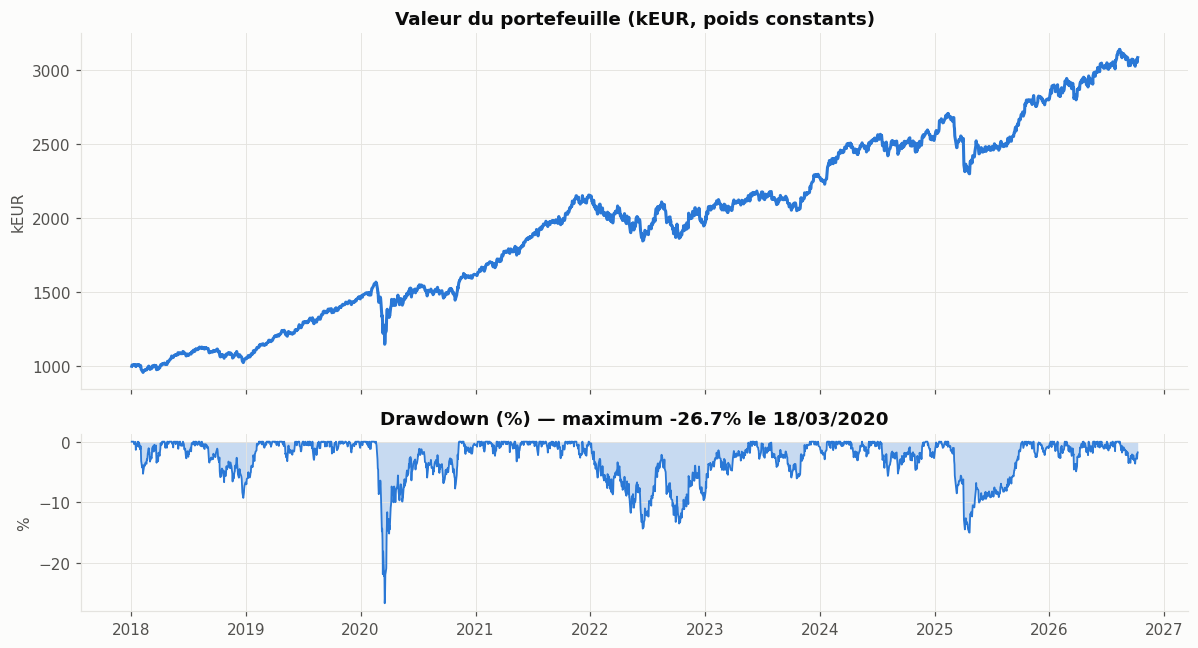

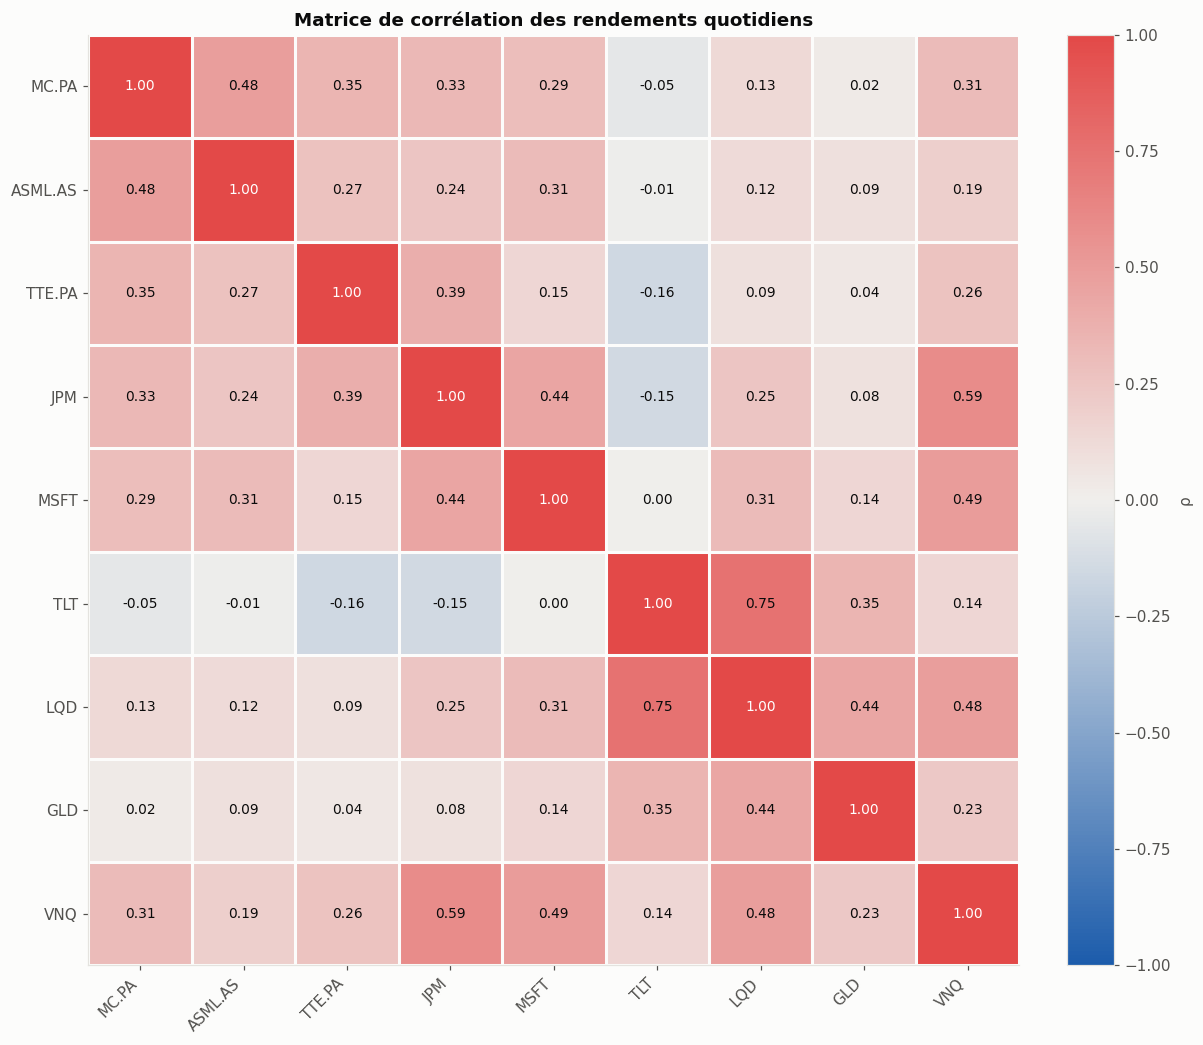

Ticker,MC.PA,ASML.AS,TTE.PA,JPM,MSFT,TLT,LQD,GLD,VNQ
Ticker,,,,,,,,,
MC.PA,0.0840,0.0502,0.0275,0.0274,0.0247,-0.0025,0.0043,0.0013,0.0197
ASML.AS,0.0502,0.1318,0.0267,0.0256,0.0330,-0.0008,0.0048,0.0059,0.0157
TTE.PA,0.0275,0.0267,0.0756,0.0307,0.0119,-0.0071,0.0027,0.0022,0.0159
JPM,0.0274,0.0256,0.0307,0.0831,0.0371,-0.0070,0.0080,0.0042,0.0377
MSFT,0.0247,0.0330,0.0119,0.0371,0.0862,0.0002,0.0102,0.0077,0.0322
TLT,-0.0025,-0.0008,-0.0071,-0.0070,0.0002,0.0276,0.0139,0.0106,0.0052
LQD,0.0043,0.0048,0.0027,0.0080,0.0102,0.0139,0.0125,0.0089,0.0120
GLD,0.0013,0.0059,0.0022,0.0042,0.0077,0.0106,0.0089,0.0332,0.0092
VNQ,0.0197,0.0157,0.0159,0.0377,0.0322,0.0052,0.0120,0.0092,0.0492


In [4]:
asset_ret = asset_prices.pct_change().dropna()            # rendements simples (agrégation entre actifs)
asset_log = np.log(asset_prices).diff().dropna()           # rendements log (statistiques annualisées)
mkt_ret = market_prices.pct_change().dropna()
port_ret = (asset_ret @ weights).rename("Portefeuille")    # poids constants
port_log = np.log1p(port_ret)

if len(asset_ret) - window < 250:
    raise InputError(f"Fenêtre de {window} jours trop longue : {len(asset_ret)} rendements disponibles, il en faut "
                     f"au moins fenêtre + 250 pour le backtest. Choisissez une fenêtre ≤ {len(asset_ret) - 250}.")


def drawdown(r):
    wealth = (1 + r).cumprod()
    return wealth / wealth.cummax() - 1


betas = pd.Series({t: np.cov(asset_ret[t], mkt_ret)[0, 1] / mkt_ret.var() for t in tickers})
beta_p = float(weights @ betas.values)


def summary_row(lr, r, beta, cls, w):
    ann_ret = lr.mean() * TRADING_DAYS
    ann_vol = lr.std() * np.sqrt(TRADING_DAYS)
    return {"Classe": cls, "Poids": w, "Rendement ann.": ann_ret, "Volatilité ann.": ann_vol,
            "Sharpe": (ann_ret - rf) / ann_vol, "Max drawdown": drawdown(r).min(), "Bêta": beta,
            "Skewness": stats.skew(r), "Kurtosis (excès)": stats.kurtosis(r), "Pire jour": r.min()}


stats_tbl = pd.DataFrame({t: summary_row(asset_log[t], asset_ret[t], betas[t], c, w)
                          for t, c, w in zip(tickers, asset_classes, weights)}).T
stats_tbl.loc["Portefeuille"] = summary_row(port_log, port_ret, beta_p, "—", 1.0)

cov_full = asset_ret.cov().values
vol_p_ann = np.sqrt(weights @ cov_full @ weights * TRADING_DAYS)
vol_w_avg = float(weights @ (asset_ret.std().values * np.sqrt(TRADING_DAYS)))

fmt = {"Poids": "{:.1%}", "Rendement ann.": "{:.1%}", "Volatilité ann.": "{:.1%}", "Sharpe": "{:.2f}",
       "Max drawdown": "{:.1%}", "Bêta": "{:.2f}", "Skewness": "{:.2f}", "Kurtosis (excès)": "{:.2f}",
       "Pire jour": "{:.2%}"}
display(stats_tbl.style.format(fmt).set_caption(f"Statistiques sur tout l'historique — {PERIOD_NOTE}"))
print(f"Volatilité du portefeuille √(wᵀΣw)·√252 = {vol_p_ann:.1%}  vs  moyenne pondérée des volatilités = "
      f"{vol_w_avg:.1%}  →  gain de diversification = {vol_w_avg - vol_p_ann:.1%}")
print(f"Bêta du portefeuille vs {market} : {beta_p:.2f}")

# Graphique 1 : valeur et drawdown du portefeuille
wealth = port_value * (1 + port_ret).cumprod()
dd = drawdown(port_ret)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax1.plot(wealth.index, wealth / 1e3, color=C1)
ax1.set_title(f"Valeur du portefeuille (k{base_ccy}, poids constants)")
ax1.set_ylabel(f"k{base_ccy}")
ax2.fill_between(dd.index, dd * 100, 0, color=C1, alpha=0.25, linewidth=0)
ax2.plot(dd.index, dd * 100, color=C1, linewidth=1.2)
ax2.set_title(f"Drawdown (%) — maximum {dd.min():.1%} le {dd.idxmin():%d/%m/%Y}")
ax2.set_ylabel("%")
fig.tight_layout()
fig.savefig(OUT_DIR / "01_valeur_drawdown.png")
plt.show()

# Graphique 2 : carte de chaleur des corrélations
corr = asset_ret.corr()
fig, ax = plt.subplots(figsize=(1.1 * n_assets + 2, 0.9 * n_assets + 1.5))
im = ax.imshow(corr.values, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(n_assets), tickers, rotation=45, ha="right")
ax.set_yticks(range(n_assets), tickers)
ax.set_xticks(np.arange(-0.5, n_assets), minor=True)
ax.set_yticks(np.arange(-0.5, n_assets), minor=True)
ax.grid(False)
ax.grid(which="minor", color=SURFACE, linewidth=2)
ax.tick_params(which="minor", length=0)
for i in range(n_assets):
    for j in range(n_assets):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9, color="white" if abs(v) > 0.8 else INK)
ax.set_title("Matrice de corrélation des rendements quotidiens")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="ρ")
fig.tight_layout()
fig.savefig(OUT_DIR / "02_correlations.png")
plt.show()

display((asset_ret.cov() * TRADING_DAYS).style.format("{:.4f}").set_caption("Matrice de covariance annualisée Σ"))

## 4. VaR et Expected Shortfall : historique, paramétrique, Monte Carlo

Estimation sur les **`window` derniers jours**, avec les poids actuels.

| Méthode | VaR | ES | Horizon *h* |
|---|---|---|---|
| Historique | −quantile$_{1-\alpha}$ des rendements passés | −moyenne des rendements ≤ −VaR | VaR(1j)·√h (règle du cours) ; variante avec rendements *h* jours chevauchants |
| Paramétrique (normale) | $z_\alpha\sigma_p-\mu_p$ | $\sigma_p\,\varphi(z_\alpha)/(1-\alpha)-\mu_p$ | $\mu h$, $\sigma\sqrt h$ |
| Monte Carlo | quantile de $w^\top r$, $r=\mu+Lz$, $\Sigma=LL^\top$ (Cholesky) | moyenne de la queue simulée | simulation directe de $N(\mu h, \Sigma h)$ |

**VaR et ES à 1 jour — portefeuille de 1,000,000 EUR**

Confiance,VaR 95%,VaR 99%,ES 95%,ES 99%
Méthode,,,,
Historique,"9,113 EUR","17,874 EUR","14,596 EUR","24,563 EUR"
Paramétrique,"10,504 EUR","15,066 EUR","13,301 EUR","17,335 EUR"
Monte Carlo,"10,713 EUR","15,345 EUR","13,577 EUR","17,880 EUR"


**VaR et ES à 10 jours — portefeuille de 1,000,000 EUR**

Confiance,VaR 95%,VaR 99%,ES 95%,ES 99%
Méthode,,,,
Historique,"28,817 EUR","56,524 EUR","46,158 EUR","77,675 EUR"
Historique (10 j chevauchants),"25,706 EUR","69,965 EUR","48,895 EUR","78,358 EUR"
Paramétrique,"29,752 EUR","44,179 EUR","38,598 EUR","51,352 EUR"
Monte Carlo,"30,413 EUR","45,059 EUR","39,470 EUR","53,077 EUR"


,Historique,Paramétrique,Monte Carlo
95.0%,1.60,1.27,1.27
99.0%,1.37,1.15,1.17


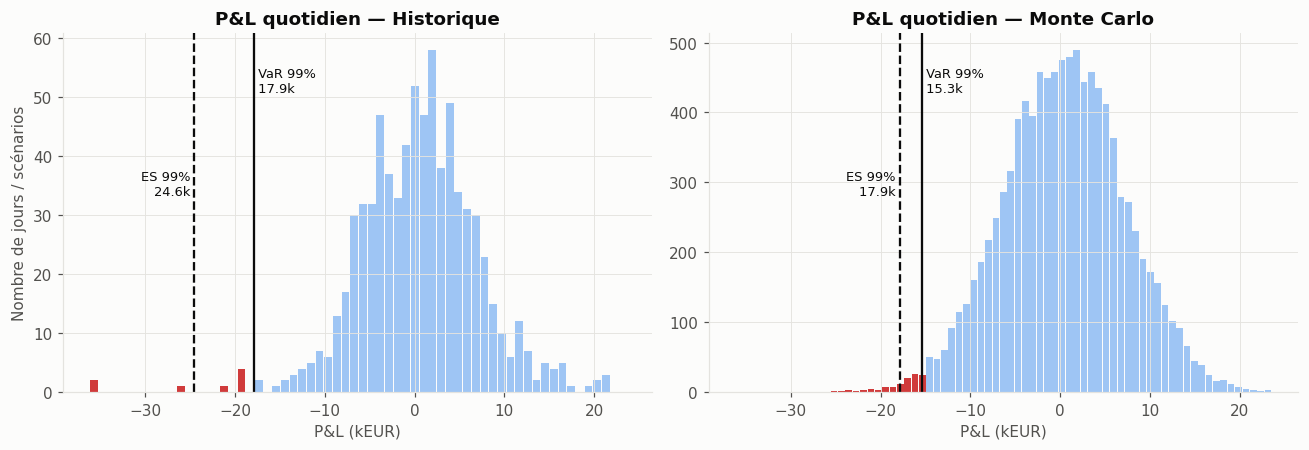

In [5]:
R_win = asset_ret.iloc[-window:]
r_win = port_ret.iloc[-window:]
mu_vec = R_win.mean().values
cov = R_win.cov().values
EST_NOTE = (f"Fenêtre d'estimation : {R_win.index[0]:%d/%m/%Y} → {R_win.index[-1]:%d/%m/%Y} ({window} jours). "
            + PERIOD_NOTE)


def sample_var_es(r, alpha):
    """VaR et ES empiriques d'un échantillon de rendements (pertes positives)."""
    r = np.asarray(r)
    q = np.quantile(r, 1 - alpha)
    return -q, -r[r <= q].mean()


def param_var_es(mu_p, sig_p, alpha):
    z = stats.norm.ppf(alpha)
    return z * sig_p - mu_p, sig_p * stats.norm.pdf(z) / (1 - alpha) - mu_p


def cov_root(c):
    """Racine L telle que LLᵀ = Σ : Cholesky, ou décomposition spectrale si Σ est singulière (ex. ρ = 1)."""
    try:
        return np.linalg.cholesky(c)
    except np.linalg.LinAlgError:
        vals, vecs = np.linalg.eigh((c + c.T) / 2)
        return vecs * np.sqrt(np.clip(vals, 0, None))


def simulate_assets(mu, c, n, h=1, seed=SEED):
    rng = np.random.default_rng(seed)
    z = rng.standard_normal((n, len(mu)))
    return mu * h + z @ cov_root(c * h).T


def model_risk(mu, c, h, alphas_, n, w=weights):
    """VaR/ES paramétriques et Monte Carlo (en rendement) pour une matrice de covariance donnée."""
    mu_p, sig_p = w @ mu * h, np.sqrt(w @ c @ w * h)
    sims_p = simulate_assets(mu, c, n, h) @ w
    res = {}
    for a in alphas_:
        res[("Paramétrique", a)] = param_var_es(mu_p, sig_p, a)
        res[("Monte Carlo", a)] = sample_var_es(sims_p, a)
    return res, sig_p, sims_p


risk = {}            # (méthode, horizon, alpha) -> (VaR, ES) en rendement
mc_samples = {}
for h in HORIZONS:
    res, _, sims_p = model_risk(mu_vec, cov, h, alphas, n_sims)
    mc_samples[h] = sims_p
    overlap = np.expm1(np.log1p(r_win).rolling(h).sum().dropna()) if h > 1 else None
    for a in alphas:
        v1, e1 = sample_var_es(r_win, a)
        risk[("Historique", h, a)] = (v1 * np.sqrt(h), e1 * np.sqrt(h))
        if h > 1:
            risk[(f"Historique ({h} j chevauchants)", h, a)] = sample_var_es(overlap, a)
        risk[("Paramétrique", h, a)] = res[("Paramétrique", a)]
        risk[("Monte Carlo", h, a)] = res[("Monte Carlo", a)]

risk_long = pd.DataFrame([{"Méthode": m, "Horizon (j)": h, "Confiance": a, "VaR (%)": v, "ES (%)": e,
                           f"VaR ({base_ccy})": v * port_value, f"ES ({base_ccy})": e * port_value}
                          for (m, h, a), (v, e) in risk.items()])


def eur(x):
    return f"{x:,.0f} {base_ccy}"


var_tables = {}
for h in HORIZONS:
    sub = risk_long[risk_long["Horizon (j)"] == h]
    tbl = pd.concat([
        sub.pivot(index="Méthode", columns="Confiance", values=f"VaR ({base_ccy})").rename(columns=lambda a: f"VaR {a:.0%}" if a * 100 == int(a * 100) else f"VaR {a:.1%}"),
        sub.pivot(index="Méthode", columns="Confiance", values=f"ES ({base_ccy})").rename(columns=lambda a: f"ES {a:.0%}" if a * 100 == int(a * 100) else f"ES {a:.1%}"),
    ], axis=1)
    order = [m for m in ["Historique", f"Historique ({h} j chevauchants)", "Paramétrique", "Monte Carlo"] if m in tbl.index]
    var_tables[h] = tbl.loc[order]
    display(Markdown(f"**VaR et ES à {h} jour{'s' if h > 1 else ''} — portefeuille de {eur(port_value)}**"))
    display(tbl.loc[order].style.format(eur).set_caption(EST_NOTE))

# Ratio ES/VaR (épaisseur de queue ; ≈ 1,15 pour une loi normale à 99 %)
ratio = pd.DataFrame({m: {f"{a:.1%}": risk[(m, 1, a)][1] / risk[(m, 1, a)][0] for a in alphas}
                      for m in ["Historique", "Paramétrique", "Monte Carlo"]})
display(ratio.style.format("{:.2f}").set_caption("Ratio ES / VaR à 1 jour (normale : 1,25 à 95 %, 1,15 à 99 %)"))
risk_long.to_csv(OUT_DIR / "var_es_results.csv", index=False)

# Graphique 3 : distributions historique et Monte Carlo avec VaR / ES
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharex=True)
for ax, (label, sample) in zip(axes, [("Historique", r_win.values), ("Monte Carlo", mc_samples[1])]):
    pnl = sample * port_value / 1e3
    var_k, es_k = (x * port_value / 1e3 for x in risk[(label, 1, a_ref)])
    counts, edges = np.histogram(pnl, bins=60)
    centers = (edges[:-1] + edges[1:]) / 2
    ax.bar(centers, counts, width=(edges[1] - edges[0]) * 0.9,
           color=[C_TAIL if c <= -var_k else C_BODY for c in centers], linewidth=0)
    ax.axvline(-var_k, color=INK, linewidth=1.5)
    ax.axvline(-es_k, color=INK, linewidth=1.5, linestyle="--")
    top = counts.max()
    ax.text(-var_k, top * 0.95, f" VaR {a_ref:.0%}\n {var_k:,.1f}k", fontsize=8.5, color=INK, va="top")
    ax.text(-es_k, top * 0.65, f"ES {a_ref:.0%} \n{es_k:,.1f}k ", fontsize=8.5, color=INK, va="top", ha="right")
    ax.set_title(f"P&L quotidien — {label}")
    ax.set_xlabel(f"P&L (k{base_ccy})")
axes[0].set_ylabel("Nombre de jours / scénarios")
fig.tight_layout()
fig.savefig(OUT_DIR / "03_distribution_var_es.png")
plt.show()

### Contribution au risque par actif

* **VaR paramétrique par composante** (décomposition d'Euler) : $\text{CVaR}_i = w_i\,(z_\alpha (\Sigma w)_i/\sigma_p - \mu_i)\cdot V$. La somme des composantes donne la VaR.
* **ES par composante** (Monte Carlo et historique) : perte moyenne de chaque position dans les scénarios de queue. La somme donne l'ES.

,Poids,Contribution à la variance,VaR param. 99% (EUR),ES MC 99% (EUR),ES hist. 99% (EUR)
MC.PA,10.0%,13.8%,"2,197 EUR","2,769 EUR","2,517 EUR"
ASML.AS,10.0%,19.9%,"2,933 EUR","3,396 EUR","2,514 EUR"
TTE.PA,10.0%,5.4%,779 EUR,996 EUR,"3,247 EUR"
JPM,10.0%,11.8%,"1,714 EUR","2,074 EUR","3,539 EUR"
MSFT,10.0%,12.0%,"1,808 EUR","2,111 EUR","3,110 EUR"
TLT,15.0%,9.4%,"1,471 EUR","1,686 EUR","1,998 EUR"
LQD,15.0%,8.2%,"1,251 EUR","1,439 EUR","2,023 EUR"
GLD,10.0%,9.8%,"1,427 EUR","1,667 EUR","2,118 EUR"
VNQ,10.0%,9.8%,"1,486 EUR","1,743 EUR","3,497 EUR"
Total,100.0%,100.0%,"15,066 EUR","17,880 EUR","24,563 EUR"


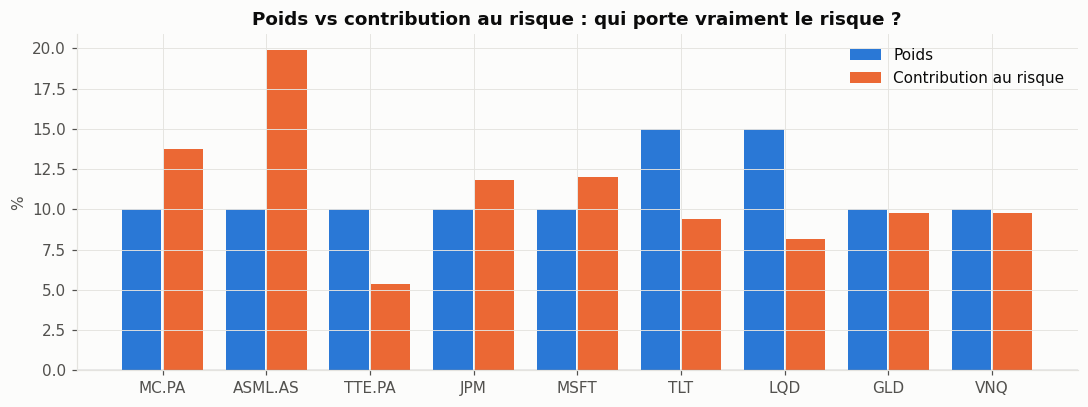

In [6]:
z_ref = stats.norm.ppf(a_ref)
sig_p1 = np.sqrt(weights @ cov @ weights)
pct_var_contrib = weights * (cov @ weights) / sig_p1**2
comp_var = weights * (z_ref * (cov @ weights) / sig_p1 - mu_vec) * port_value

sims1 = simulate_assets(mu_vec, cov, n_sims, 1)
p1 = sims1 @ weights
tail_mc = p1 <= np.quantile(p1, 1 - a_ref)
comp_es_mc = -(sims1[tail_mc] * weights).mean(axis=0) * port_value
tail_h = r_win.values <= np.quantile(r_win.values, 1 - a_ref)
comp_es_hist = -(R_win.values[tail_h] * weights).mean(axis=0) * port_value

contrib = pd.DataFrame({
    "Poids": weights,
    "Contribution à la variance": pct_var_contrib,
    f"VaR param. {a_ref:.0%} ({base_ccy})": comp_var,
    f"ES MC {a_ref:.0%} ({base_ccy})": comp_es_mc,
    f"ES hist. {a_ref:.0%} ({base_ccy})": comp_es_hist,
}, index=tickers)
contrib.loc["Total"] = contrib.sum()
display(contrib.style.format({"Poids": "{:.1%}", "Contribution à la variance": "{:.1%}"} |
                             {c: eur for c in contrib.columns[2:]})
        .set_caption(f"Contribution au risque à 1 jour — {EST_NOTE}"))
contrib.to_csv(OUT_DIR / "risk_contributions.csv")

fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(n_assets)
ax.bar(x - 0.2, weights * 100, width=0.38, color=C1, label="Poids")
ax.bar(x + 0.2, pct_var_contrib * 100, width=0.38, color=C2, label="Contribution au risque")
ax.set_xticks(x, tickers)
ax.set_ylabel("%")
ax.set_title("Poids vs contribution au risque : qui porte vraiment le risque ?")
ax.legend(loc="upper right")
ax.axhline(0, color=INK2, linewidth=0.8)
fig.tight_layout()
fig.savefig(OUT_DIR / "04_contributions.png")
plt.show()

## 5. Backtest glissant : exceptions, test de Kupiec, feux tricolores

Chaque jour *t* après la première fenêtre, la VaR à 1 jour est estimée sur les `window` jours précédents, puis comparée au rendement réalisé en *t*. Il y a **exception** quand la perte dépasse la VaR.

* **Kupiec (POF)** : $LR = -2\ln\frac{(1-p)^{N-x}p^x}{(1-\hat p)^{N-x}\hat p^x} \sim \chi^2_1$, avec $\hat p = x/N$. On rejette le modèle si la p-value est < 5 %.
* **Feux tricolores de Bâle** (250 derniers jours, 99 % : vert 0–4, orange 5–9, rouge ≥ 10). Formule générale : vert si $P(X\le x) < 95\,\%$, orange si $< 99{,}99\,\%$, rouge sinon, avec $X\sim\text{Binomiale}(N, 1-\alpha)$.

Pour aller plus vite, le Monte Carlo du backtest réutilise les mêmes tirages aléatoires chaque jour (nombres aléatoires communs, 5 000 scénarios au maximum).

Backtest en cours...


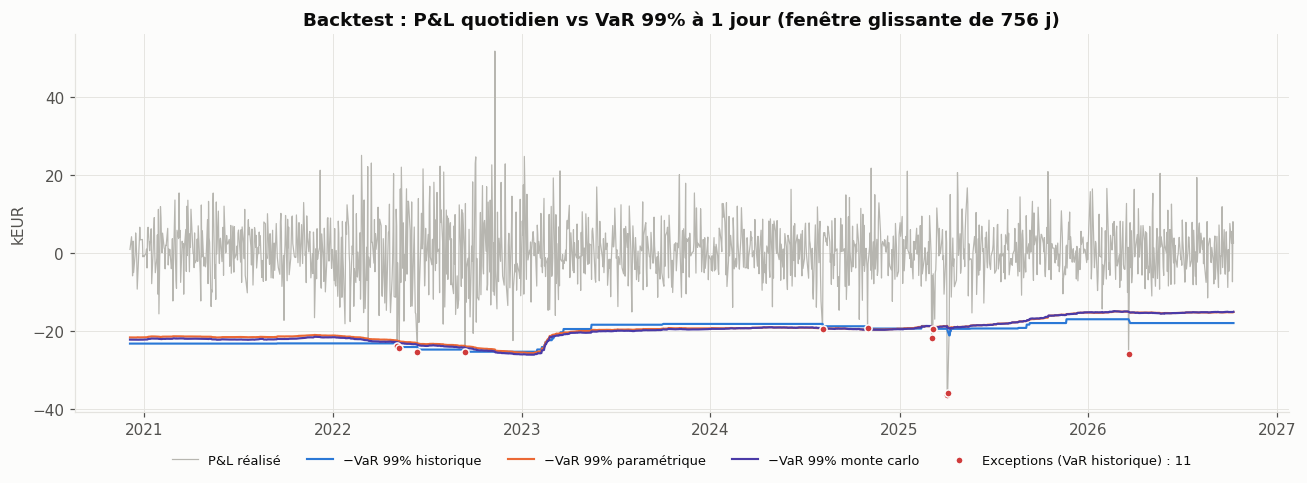

In [7]:
def rolling_var(asset_returns, w, win, alphas_, n_bt, seed=SEED):
    R = asset_returns.values
    rp = R @ w
    T = len(R)
    Z = np.random.default_rng(seed).standard_normal((n_bt, R.shape[1]))
    zs = {a: stats.norm.ppf(a) for a in alphas_}
    out = {f"{m} {a:.1%}": np.empty(T - win) for m in ["Historique", "Paramétrique", "Monte Carlo"] for a in alphas_}
    for i, t in enumerate(range(win, T)):
        Rw, rw = R[t - win:t], rp[t - win:t]
        mu, C = Rw.mean(axis=0), np.cov(Rw, rowvar=False)
        mu_p, s_p = mu @ w, np.sqrt(w @ C @ w)
        sim_p = mu_p + Z @ (cov_root(C).T @ w)
        for a in alphas_:
            out[f"Historique {a:.1%}"][i] = -np.quantile(rw, 1 - a)
            out[f"Paramétrique {a:.1%}"][i] = zs[a] * s_p - mu_p
            out[f"Monte Carlo {a:.1%}"][i] = -np.quantile(sim_p, 1 - a)
    df = pd.DataFrame(out, index=asset_returns.index[win:])
    df["Rendement réalisé"] = rp[win:]
    return df


def kupiec_pof(x, n, p):
    phat = x / n
    lr = -2 * ((xlogy(n - x, 1 - p) + xlogy(x, p)) - (xlogy(n - x, 1 - phat) + xlogy(x, phat)))
    return lr, 1 - stats.chi2.cdf(lr, 1)


def traffic_light(x, n, p):
    c = stats.binom.cdf(x, n, p)
    return "🟢 Vert" if c < 0.95 else ("🟠 Orange" if c < 0.9999 else "🔴 Rouge")


print("Backtest en cours...")
bt = rolling_var(asset_ret, weights, window, alphas, min(n_sims, 5000))
rows = []
for m in ["Historique", "Paramétrique", "Monte Carlo"]:
    for a in alphas:
        exc = bt["Rendement réalisé"] < -bt[f"{m} {a:.1%}"]
        n, x = len(exc), int(exc.sum())
        lr, pv = kupiec_pof(x, n, 1 - a)
        x250 = int(exc.iloc[-250:].sum())
        rows.append({"Méthode": m, "Confiance": f"{a:.1%}", "Jours testés": n, "Exceptions": x,
                     "Attendues": n * (1 - a), "Taux observé": x / n, "LR Kupiec": lr, "p-value": pv,
                     "Kupiec (5 %)": "✓ non rejeté" if pv >= 0.05 else
                     ("✗ rejeté (trop d'exceptions)" if x > n * (1 - a) else "✗ rejeté (trop peu : VaR conservatrice)"),
                     "Exceptions 250 derniers j": x250,
                     "Feu (250 derniers j)": traffic_light(x250, 250, 1 - a),
                     "Feu (échantillon)": traffic_light(x, n, 1 - a)})
bt_tbl = pd.DataFrame(rows).set_index(["Méthode", "Confiance"])
display(bt_tbl.style.format({"Attendues": "{:.1f}", "Taux observé": "{:.2%}", "LR Kupiec": "{:.2f}",
                             "p-value": "{:.3f}"})
        .set_caption(f"Backtest {bt.index[0]:%d/%m/%Y} → {bt.index[-1]:%d/%m/%Y}, fenêtre glissante de {window} j. "
                     "Feux tricolores : référence bâloise à 99 % sur 250 jours, généralisée par la loi binomiale."))
bt.to_csv(OUT_DIR / "backtest_series.csv")
bt_tbl.to_csv(OUT_DIR / "backtest_summary.csv")

# Graphique 4 : P&L réalisé vs VaR glissante
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(bt.index, bt["Rendement réalisé"] * port_value / 1e3, color="#b7b6b0", linewidth=0.8, label="P&L réalisé")
for m, c in zip(["Historique", "Paramétrique", "Monte Carlo"], [C1, C2, C4]):
    ax.plot(bt.index, -bt[f"{m} {a_ref:.1%}"] * port_value / 1e3, color=c, linewidth=1.4, label=f"−VaR {a_ref:.0%} {m.lower()}")
exc = bt["Rendement réalisé"] < -bt[f"Historique {a_ref:.1%}"]
ax.scatter(bt.index[exc], bt.loc[exc, "Rendement réalisé"] * port_value / 1e3, s=22, color=C_TAIL,
           edgecolor=SURFACE, linewidth=1, zorder=5, label=f"Exceptions (VaR historique) : {int(exc.sum())}")
ax.set_title(f"Backtest : P&L quotidien vs VaR {a_ref:.0%} à 1 jour (fenêtre glissante de {window} j)")
ax.set_ylabel(f"k{base_ccy}")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=5, fontsize=8.5)
fig.tight_layout()
fig.savefig(OUT_DIR / "05_backtest.png")
plt.show()

## 6. Module de stress tests

| Scénario | Ce qu'on vous demande | Résultat |
|---|---|---|
| Épisode historique | choisir des fenêtres (2008, mars 2020, 2022...) rejouées sur les poids actuels | perte en € et %, actif le plus pénalisant |
| Choc hypothétique | un % par actif, ou un choc de marché transmis par les bêtas | perte par actif |
| Stress de corrélation | ρ* entre 0,8 et 1 pour toutes les paires | nouvelle volatilité, VaR, ES |
| Stress de volatilité | volatilités × k, avec k entre 1,5 et 3 | nouvelle VaR, ES |
| Stress inverse | une limite de perte (ex. 20 %) | chocs qui la franchissent |

Chaque perte est rapportée à la **VaR et à l'ES historiques à `a_ref`** (99 % par défaut), à 1 jour et à *h* jours.

Épisodes historiques disponibles :
   1. Crise financière mondiale 2007-2009 (2007-10-09 → 2009-03-09)
   2. Faillite de Lehman Brothers (sept.-nov. 2008) (2008-09-12 → 2008-11-20)
   3. Krach du Covid (févr.-mars 2020) (2020-02-19 → 2020-03-23)
   4. Choc de taux 2022 (2022-01-03 → 2022-10-12)
   5. Éclatement de la bulle internet 2000-2002 (2000-03-24 → 2002-10-09)
   6. Black Monday 1987 (1987-10-16 → 1987-10-19)
   c. Fenêtre personnalisée


**Crise financière mondiale 2007-2009** (09/10/2007 → 09/03/2009, achat-conservation sur les poids actuels) : perte **19.05% = 190,468 EUR**, actif le plus pénalisant : **VNQ**

,Poids,Rendement,Contribution,Source
Actif,,,,
MC.PA,10.0%,-48.12%,-4.81%,Historique
ASML.AS,10.0%,-47.87%,-4.79%,Historique
TTE.PA,10.0%,-30.28%,-3.03%,Historique
JPM,10.0%,-60.82%,-6.08%,Historique
MSFT,10.0%,-42.13%,-4.21%,Historique
TLT,15.0%,39.78%,5.97%,Historique
LQD,15.0%,4.19%,0.63%,Historique
GLD,10.0%,38.49%,3.85%,Historique
VNQ,10.0%,-65.70%,-6.57%,Historique


**Krach du Covid (févr.-mars 2020)** (19/02/2020 → 23/03/2020, achat-conservation sur les poids actuels) : perte **20.06% = 200,586 EUR**, actif le plus pénalisant : **JPM**

,Poids,Rendement,Contribution,Source
Actif,,,,
MC.PA,10.0%,-25.69%,-2.57%,Historique
ASML.AS,10.0%,-27.11%,-2.71%,Historique
TTE.PA,10.0%,-41.18%,-4.12%,Historique
JPM,10.0%,-41.98%,-4.20%,Historique
MSFT,10.0%,-26.71%,-2.67%,Historique
TLT,15.0%,15.31%,2.30%,Historique
LQD,15.0%,-11.47%,-1.72%,Historique
GLD,10.0%,-2.71%,-0.27%,Historique
VNQ,10.0%,-40.99%,-4.10%,Historique


...

,Poids,Choc,Contribution,Perte (EUR)
MC.PA,10.0%,-20.00%,-2.00%,"20,000 EUR"
ASML.AS,10.0%,-25.00%,-2.50%,"25,000 EUR"
TTE.PA,10.0%,5.00%,0.50%,"-5,000 EUR"
JPM,10.0%,-12.00%,-1.20%,"12,000 EUR"
MSFT,10.0%,-15.00%,-1.50%,"15,000 EUR"
TLT,15.0%,-8.00%,-1.20%,"12,000 EUR"
LQD,15.0%,-6.00%,-0.90%,"9,000 EUR"
GLD,10.0%,8.00%,0.80%,"-8,000 EUR"
VNQ,10.0%,-15.00%,-1.50%,"15,000 EUR"


Corrélations ρ* = 0.90 : VaR paramétrique 99% à 1 jour 15,066 EUR → 29,656 EUR (×1.97)
Volatilités × 2 : VaR paramétrique 99% à 1 jour 15,066 EUR → 30,639 EUR (×2.03)
Pour comparaison, avec ρ = 1 partout : volatilité = moyenne pondérée des volatilités = 21.6%


,Poids,Choc uniforme,Choc isolé nécessaire,Via le marché (β × choc SPY),Le plus vraisemblable (10 j)
MC.PA,10.0%,-20.0%,impossible seul,-20.8%,-28.8%
ASML.AS,10.0%,-20.0%,impossible seul,-27.4%,-39.1%
TTE.PA,10.0%,-20.0%,impossible seul,-15.8%,-10.5%
JPM,10.0%,-20.0%,impossible seul,-38.9%,-23.0%
MSFT,10.0%,-20.0%,impossible seul,-42.9%,-24.0%
TLT,15.0%,-20.0%,impossible seul,-0.7%,-12.9%
LQD,15.0%,-20.0%,impossible seul,-9.3%,-11.0%
GLD,10.0%,-20.0%,impossible seul,-7.8%,-19.1%
VNQ,10.0%,-20.0%,impossible seul,-31.3%,-19.7%


• Choc uniforme : tous les actifs à −20%.
• Via le marché : il faut que SPY perde 37.2% (bêta du portefeuille 0.54).
• Scénario le plus vraisemblable sous la loi normale à 10 j : à 9.7 σ, probabilité ≈ 1.71e-22.
• Fréquence historique d'une perte ≥ 20% sur 10 jours glissants : 0.04% (pire perte observée sur 10 j : 21.7%).


,Famille,Mesure,Perte (%),Perte (EUR),Actif moteur,÷ VaR 99% 1 j,÷ ES 99% 1 j,÷ VaR 99% 10 j,÷ ES 99% 10 j
Scénario,,,,,,,,,
Crise financière mondiale 2007-2009,Historique,Perte du scénario,19.05%,"190,468 EUR",VNQ,10.7×,7.8×,3.4×,2.5×
Krach du Covid (févr.-mars 2020),Historique,Perte du scénario,20.06%,"200,586 EUR",JPM,11.2×,8.2×,3.5×,2.6×
Choc de taux 2022,Historique,Perte du scénario,13.04%,"130,412 EUR",ASML.AS,7.3×,5.3×,2.3×,1.7×
Choc de marché -20% via les bêtas,Hypothétique,Perte du scénario,10.76%,"107,583 EUR",MSFT,6.0×,4.4×,1.9×,1.4×
Chocs personnalisés par actif,Hypothétique,Perte du scénario,9.50%,"95,000 EUR",ASML.AS,5.3×,3.9×,1.7×,1.2×
Corrélations ρ* = 0.90,Corrélation,VaR 99% param. 1 j stressée,2.97%,"29,656 EUR",—,1.7×,1.2×,0.5×,0.4×
Volatilités × 2,Volatilité,VaR 99% param. 1 j stressée,3.06%,"30,639 EUR",—,1.7×,1.2×,0.5×,0.4×
Stress inverse : limite 20%,Inverse,Limite de perte,20.00%,"200,000 EUR",ASML.AS,11.2×,8.1×,3.5×,2.6×


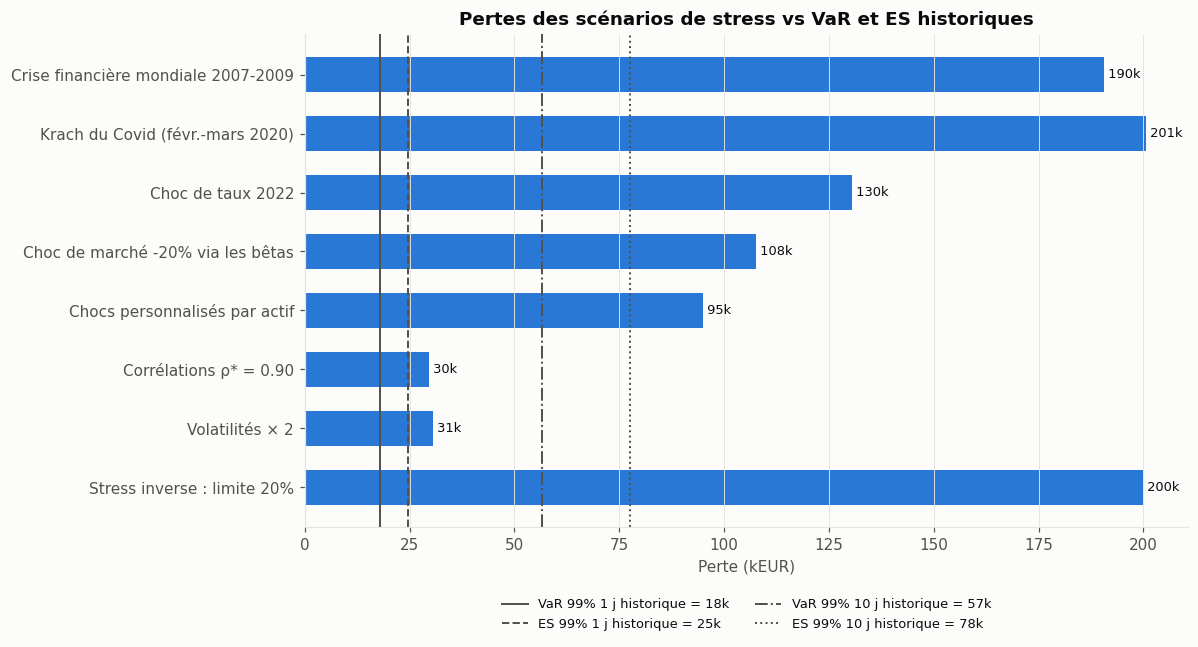

In [8]:
stress_rows = []
ref_var1, ref_es1 = risk[("Historique", 1, a_ref)]
ref_varh, ref_esh = risk[("Historique", horizon, a_ref)]


def record_stress(name, family, loss_pct, driver="—", measure="Perte du scénario"):
    stress_rows.append({"Scénario": name, "Famille": family, "Mesure": measure, "Perte (%)": loss_pct,
                        f"Perte ({base_ccy})": loss_pct * port_value, "Actif moteur": driver})


# ---------------- 6.1 Épisodes historiques ----------------
EPISODES = {
    "1": ("Crise financière mondiale 2007-2009", "2007-10-09", "2009-03-09"),
    "2": ("Faillite de Lehman Brothers (sept.-nov. 2008)", "2008-09-12", "2008-11-20"),
    "3": ("Krach du Covid (févr.-mars 2020)", "2020-02-19", "2020-03-23"),
    "4": ("Choc de taux 2022", "2022-01-03", "2022-10-12"),
    "5": ("Éclatement de la bulle internet 2000-2002", "2000-03-24", "2002-10-09"),
    "6": ("Black Monday 1987", "1987-10-16", "1987-10-19"),
}
print("Épisodes historiques disponibles :")
for k, (n_, s_, e_) in EPISODES.items():
    print(f"   {k}. {n_} ({s_} → {e_})")
print("   c. Fenêtre personnalisée")


def parse_episode_choice(s):
    keys = [k.strip().lower() for k in re.split(r"[,;\s]+", s) if k.strip()]
    bad = [k for k in keys if k not in EPISODES and k != "c"]
    if bad or not keys:
        raise InputError(f"choix inconnu(s) : {bad or 'aucun'} ; tapez des numéros de la liste ou 'c'.")
    return keys


episode_keys = ask("Épisodes à rejouer (au moins 3 pour le projet)", "1, 3, 4", parse_episode_choice)
episodes = []
for k in episode_keys:
    if k == "c":
        cs = ask("Début de la fenêtre personnalisée", "2018-10-01", parse_date)
        ce = ask("Fin de la fenêtre personnalisée", "2018-12-24", parse_date)
        if ce <= cs:
            raise InputError("la fin de la fenêtre personnalisée doit suivre son début.")
        episodes.append((f"Fenêtre personnalisée {cs:%Y-%m-%d} → {ce:%Y-%m-%d}", cs, ce))
    else:
        n_, s_, e_ = EPISODES[k]
        episodes.append((n_, pd.Timestamp(s_), pd.Timestamp(e_)))


def window_return(series, start, end):
    s = series.dropna()
    if s.empty or s.index[0] > start + pd.Timedelta(days=5) or s.index[-1] < end - pd.Timedelta(days=5):
        return np.nan                     # l'actif n'existait pas (ou pas de cotation) sur la fenêtre
    return s.asof(end) / s.asof(start) - 1


def replay_episode(name, start, end):
    proxies = list(dict.fromkeys([market, "^GSPC"]))
    universe_ = list(dict.fromkeys(tickers + proxies))
    lo, hi = start - pd.Timedelta(days=10), end + pd.Timedelta(days=5)
    raw_ep = download_close(universe_, lo, hi)
    ccys = dict(currencies) | {"^GSPC": "USD"}

    def ret_base(t):
        r = window_return(raw_ep[t], start, end) if t in raw_ep else np.nan
        if np.isnan(r):
            return np.nan, ""
        ccy, _ = normalise_currency(ccys.get(t))
        if ccy == base_ccy:
            return r, ""
        try:
            fx_r = window_return(fx_series(ccy, base_ccy, lo, hi, {}), start, end)
        except RuntimeError:
            fx_r = np.nan
        if np.isnan(fx_r):
            return r, f" (en {ccy}, change {ccy}/{base_ccy} indisponible)"
        return (1 + r) * (1 + fx_r) - 1, ""

    proxy_ret, proxy_name = np.nan, None
    for p in proxies:
        proxy_ret, _ = ret_base(p)
        if not np.isnan(proxy_ret):
            proxy_name = p
            break
    rows_ = []
    for t, w in zip(tickers, weights):
        r, note = ret_base(t)
        source = "Historique" + note
        if np.isnan(r):
            if proxy_name is None:
                return None
            r = max(betas[t] * proxy_ret, -1.0)
            source = f"Proxy : β={betas[t]:.2f} × {proxy_name}"
        rows_.append({"Actif": t, "Poids": w, "Rendement": r, "Contribution": w * r, "Source": source})
    return pd.DataFrame(rows_).set_index("Actif")


episode_tables = []
for name, s_, e_ in episodes:
    tbl = replay_episode(name, s_, e_)
    if tbl is None:
        print(f"⚠ {name} : aucune donnée, même pour les proxys ; scénario ignoré.")
        continue
    loss = -tbl["Contribution"].sum()
    driver = tbl["Contribution"].idxmin()
    record_stress(name, "Historique", loss, driver)
    episode_tables.append((name, s_, e_, loss, driver, tbl))
    display(Markdown(f"**{name}** ({s_:%d/%m/%Y} → {e_:%d/%m/%Y}, achat-conservation sur les poids actuels) : "
                     f"perte **{loss:.2%} = {eur(loss * port_value)}**, actif le plus pénalisant : **{driver}**"))
    display(tbl.style.format({"Poids": "{:.1%}", "Rendement": "{:.2%}", "Contribution": "{:.2%}"}))

# ---------------- 6.2 Chocs hypothétiques ----------------
def validate_shock(x):
    if not -100 < x < 1000:
        raise InputError("le choc doit être compris entre −100 % (exclu) et +1000 %.")


mkt_shock = ask(f"Choc de marché sur {market} (%) transmis via les bêtas (0 = aucun)", "-20", parse_number,
                validate_shock) / 100


def parse_shocks(s):
    if s.strip().lower() in {"aucun", "none", "non", "0", "skip"}:
        return {}
    out = {}
    for item in re.split(r"[,;]+", s):
        if not item.strip():
            continue
        if ":" not in item:
            raise InputError(f"« {item.strip()} » : format attendu TICKER:CHOC, ex. NVDA:-20.")
        t, v = item.split(":", 1)
        t = t.strip().upper()
        if t not in tickers:
            raise InputError(f"{t} ne fait pas partie du portefeuille {tickers}.")
        v = parse_number(v)
        validate_shock(v)
        out[t] = v / 100
    return out


# Défaut : choc de stagflation (actions et obligations baissent ensemble, énergie et or montent)
default_shocks = ("MC.PA:-20, ASML.AS:-25, TTE.PA:5, JPM:-12, MSFT:-15, TLT:-8, LQD:-6, GLD:8, VNQ:-15"
                  if is_default_portfolio else "aucun")
custom_shocks = ask("Chocs par actif 'TICKER:%' (actifs non cités = 0 ; 'aucun' pour passer)", default_shocks,
                    parse_shocks)

hypo_tables = []
if mkt_shock != 0:
    shocks = np.maximum(betas.values * mkt_shock, -1)
    tbl = pd.DataFrame({"Poids": weights, "Bêta": betas.values, "Choc": shocks, "Contribution": weights * shocks},
                       index=tickers)
    loss = -tbl["Contribution"].sum()
    name = f"Choc de marché {mkt_shock:+.0%} via les bêtas"
    record_stress(name, "Hypothétique", loss, tbl["Contribution"].idxmin())
    hypo_tables.append((name, loss, tbl))
    display(Markdown(f"**{name}** : perte **{loss:.2%} = {eur(loss * port_value)}**"))
    display(tbl.style.format({"Poids": "{:.1%}", "Bêta": "{:.2f}", "Choc": "{:.2%}", "Contribution": "{:.2%}"}))

if custom_shocks:
    shocks = np.array([custom_shocks.get(t, 0.0) for t in tickers])
    tbl = pd.DataFrame({"Poids": weights, "Choc": shocks, "Contribution": weights * shocks,
                        f"Perte ({base_ccy})": -weights * shocks * port_value}, index=tickers)
    loss = -tbl["Contribution"].sum()
    name = "Chocs personnalisés par actif"
    record_stress(name, "Hypothétique", loss, tbl["Contribution"].idxmin())
    hypo_tables.append((name, loss, tbl))
    display(Markdown(f"**{name}** : perte **{loss:.2%} = {eur(loss * port_value)}**"))
    display(tbl.style.format({"Poids": "{:.1%}", "Choc": "{:.2%}", "Contribution": "{:.2%}", f"Perte ({base_ccy})": eur}))

# ---------------- 6.3 Stress de corrélation et de volatilité ----------------
rho_star = ask("Corrélation de crise ρ* (entre 0,8 et 1)", "0.9", parse_number,
               lambda x: validate_range(0.8, 1.0, "ρ*")(x))
k_vol = ask("Multiplicateur de volatilité k (entre 1,5 et 3)", "2", parse_number,
            lambda x: validate_range(1.5, 3.0, "k")(x))

vols = np.sqrt(np.diag(cov))
corr_star = np.full((n_assets, n_assets), rho_star)
np.fill_diagonal(corr_star, 1.0)
cov_corr = np.outer(vols, vols) * corr_star
cov_vol = cov * k_vol**2

model_rows = []
for label, c in [("Base (estimée)", cov), (f"Corrélations ρ* = {rho_star:.2f}", cov_corr),
                 (f"Volatilités × {k_vol:g}", cov_vol)]:
    for h in HORIZONS:
        res, sig_h, _ = model_risk(mu_vec, c, h, alphas, n_sims)
        row = {"Scénario": label, "Horizon (j)": h, "Vol. ann.": np.sqrt(weights @ c @ weights * TRADING_DAYS)}
        for a in alphas:
            for m, short in [("Paramétrique", "param."), ("Monte Carlo", "MC")]:
                v, e = res[(m, a)]
                row[f"VaR {a:.0%} {short}"] = v * port_value
                row[f"ES {a:.0%} {short}"] = e * port_value
        model_rows.append(row)
model_tbl = pd.DataFrame(model_rows).set_index(["Scénario", "Horizon (j)"])
display(model_tbl.style.format({"Vol. ann.": "{:.1%}"} | {c: eur for c in model_tbl.columns[1:]})
        .set_caption("Stress de corrélation et de volatilité : moyenne μ inchangée, mêmes tirages aléatoires que le cas de base"))
base_param = model_tbl.loc[("Base (estimée)", 1), f"VaR {a_ref:.0%} param."]
for label in [f"Corrélations ρ* = {rho_star:.2f}", f"Volatilités × {k_vol:g}"]:
    v = model_tbl.loc[(label, 1), f"VaR {a_ref:.0%} param."]
    record_stress(label, "Corrélation" if "ρ" in label else "Volatilité", v / port_value,
                  measure=f"VaR {a_ref:.0%} param. 1 j stressée")
    print(f"{label} : VaR paramétrique {a_ref:.0%} à 1 jour {eur(base_param)} → {eur(v)} (×{v / base_param:.2f})")
print(f"Pour comparaison, avec ρ = 1 partout : volatilité = moyenne pondérée des volatilités = "
      f"{float(weights @ vols) * np.sqrt(TRADING_DAYS):.1%}")

# ---------------- 6.4 Stress inverse ----------------
loss_limit = ask("Limite de perte pour le stress inverse (% de la valeur)", "20", parse_number,
                 lambda x: validate_range(0.1, 100, "la limite de perte")(x)) / 100
L = loss_limit
w_cov = cov @ weights
var_p = weights @ w_cov
mu_ph, sig_ph = weights @ mu_vec * horizon, np.sqrt(var_p * horizon)
# Scénario le plus vraisemblable sous N(μh, Σh) tel que wᵀr = −L (point de Mahalanobis minimal)
r_star = mu_vec * horizon - (L + mu_ph) * w_cov / var_p
d_sigma = (L + mu_ph) / sig_ph
p_normal = stats.norm.cdf(-d_sigma)
roll_h = np.expm1(np.log1p(port_ret).rolling(horizon).sum().dropna())
freq_hist = float((roll_h <= -L).mean())

rev = pd.DataFrame({
    "Poids": weights,
    "Choc uniforme": -L,
    "Choc isolé nécessaire": [(-L / w if w > 0 and L / w <= 1 else np.nan) for w in weights],
    f"Via le marché (β × choc {market})": betas.values * (-L / beta_p) if beta_p > 0 else np.nan,
    f"Le plus vraisemblable ({horizon} j)": r_star,
}, index=tickers)
display(rev.style.format("{:.1%}", na_rep="impossible seul")
        .set_caption(f"Stress inverse : chocs qui font perdre {L:.0%} = {eur(L * port_value)}"))
reverse_notes = [f"Choc uniforme : tous les actifs à −{L:.0%}."]
if beta_p > 0:
    reverse_notes.append(f"Via le marché : il faut que {market} perde {L / beta_p:.1%} (bêta du portefeuille {beta_p:.2f}).")
reverse_notes += [
    f"Scénario le plus vraisemblable sous la loi normale à {horizon} j : à {d_sigma:.1f} σ, probabilité ≈ {p_normal:.2e}.",
    f"Fréquence historique d'une perte ≥ {L:.0%} sur {horizon} jours glissants : {freq_hist:.2%} "
    f"(pire perte observée sur {horizon} j : {-roll_h.min():.1%}).",
]
for note in reverse_notes:
    print("• " + note)
record_stress(f"Stress inverse : limite {L:.0%}", "Inverse", L, tickers[int(np.argmin(weights * r_star))],
              measure="Limite de perte")

# ---------------- 6.5 Synthèse : stress vs VaR / ES ----------------
stress_tbl = pd.DataFrame(stress_rows).set_index("Scénario")
stress_tbl[f"÷ VaR {a_ref:.0%} 1 j"] = stress_tbl["Perte (%)"] / ref_var1
stress_tbl[f"÷ ES {a_ref:.0%} 1 j"] = stress_tbl["Perte (%)"] / ref_es1
stress_tbl[f"÷ VaR {a_ref:.0%} {horizon} j"] = stress_tbl["Perte (%)"] / ref_varh
stress_tbl[f"÷ ES {a_ref:.0%} {horizon} j"] = stress_tbl["Perte (%)"] / ref_esh
display(stress_tbl.style.format({"Perte (%)": "{:.2%}", f"Perte ({base_ccy})": eur} |
                                {c: "{:.1f}×" for c in stress_tbl.columns if c.startswith("÷")})
        .set_caption(f"Stress tests vs VaR / ES historiques (VaR {a_ref:.0%} 1 j = {eur(ref_var1 * port_value)}, "
                     f"ES = {eur(ref_es1 * port_value)}). {PERIOD_NOTE}"))
stress_tbl.to_csv(OUT_DIR / "stress_tests.csv")

fig, ax = plt.subplots(figsize=(11, 0.55 * len(stress_tbl) + 1.6))
vals = stress_tbl[f"Perte ({base_ccy})"] / 1e3
ax.barh(range(len(vals)), vals, color=C1, height=0.6)
ax.set_yticks(range(len(vals)), stress_tbl.index)
ax.invert_yaxis()
for y, v in enumerate(vals):
    ax.text(v, y, f" {v:,.0f}k", va="center", fontsize=8.5, color=INK)
for ref, ls, lab in [(ref_var1, "-", f"VaR {a_ref:.0%} 1 j"), (ref_es1, "--", f"ES {a_ref:.0%} 1 j"),
                     (ref_varh, "-.", f"VaR {a_ref:.0%} {horizon} j"), (ref_esh, ":", f"ES {a_ref:.0%} {horizon} j")]:
    ax.axvline(ref * port_value / 1e3, color=INK2, linestyle=ls, linewidth=1.3,
               label=f"{lab} historique = {ref * port_value / 1e3:,.0f}k")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=8.5)
ax.set_xlabel(f"Perte (k{base_ccy})")
ax.set_title("Pertes des scénarios de stress vs VaR et ES historiques")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(OUT_DIR / "06_stress.png")
plt.show()

## 7. Analyses complémentaires
### 7.1 La diversification en période de crise (question 3)

In [9]:
def regime_stats(R):
    c = R.corr().values
    avg_rho = c[np.triu_indices_from(c, 1)].mean()
    C = R.cov().values
    vol_p = np.sqrt(weights @ C @ weights * TRADING_DAYS)
    vol_avg = float(weights @ (R.std().values * np.sqrt(TRADING_DAYS)))
    return {"Jours": len(R), "Corrélation moyenne": avg_rho, "Vol. portefeuille": vol_p,
            "Ratio de diversification": vol_avg / vol_p}


mkt_q = mkt_ret.quantile(0.05)
regimes = {
    "Tout l'historique": asset_ret,
    "Krach Covid (19/02 – 30/04/2020)": asset_ret.loc["2020-02-19":"2020-04-30"],
    "Année 2022": asset_ret.loc["2022-01-01":"2022-12-31"],
    f"5 % des pires jours de {market}": asset_ret[mkt_ret <= mkt_q],
    f"Jours calmes (|{market}| < médiane)": asset_ret[mkt_ret.abs() < mkt_ret.abs().median()],
}
regime_tbl = pd.DataFrame({k: regime_stats(v) for k, v in regimes.items() if len(v) > n_assets + 5}).T
display(regime_tbl.style.format({"Jours": "{:.0f}", "Corrélation moyenne": "{:.2f}", "Vol. portefeuille": "{:.1%}",
                                 "Ratio de diversification": "{:.2f}"})
        .set_caption("Ratio de diversification = moyenne pondérée des volatilités / volatilité du portefeuille (1 = aucune diversification)"))

,Jours,Corrélation moyenne,Vol. portefeuille,Ratio de diversification
Tout l'historique,2267,0.23,13.2%,1.77
Krach Covid (19/02 – 30/04/2020),51,0.38,43.3%,1.44
Année 2022,258,0.34,17.8%,1.55
5 % des pires jours de SPY,114,0.26,18.9%,1.68
Jours calmes (|SPY| < médiane),1133,0.06,7.1%,2.46


### 7.2 Effet de la concentration (question 7)

In [10]:
most_vol = stats_tbl.drop("Portefeuille")["Volatilité ann."].astype(float).idxmax()
i_mv = tickers.index(most_vol)


def tilt(w, i, target):
    """Porte le poids de l'actif i à `target` et réduit les autres proportionnellement."""
    w = w.copy()
    others = np.arange(len(w)) != i
    w[others] = w[others] / w[others].sum() * (1 - target) if w[others].sum() > 0 else (1 - target) / others.sum()
    w[i] = target
    return w


variants = {"Équipondéré": np.full(n_assets, 1 / n_assets), "Portefeuille actuel": weights,
            f"50 % sur {most_vol}": tilt(weights, i_mv, 0.5), f"100 % sur {most_vol}": tilt(weights, i_mv, 1.0)}
conc_rows = {}
for label, wv in variants.items():
    rp_win = R_win.values @ wv
    hv, he = sample_var_es(rp_win, a_ref)
    pv_, pe_ = param_var_es(wv @ mu_vec, np.sqrt(wv @ cov @ wv), a_ref)
    conc_rows[label] = {"HHI": float(wv @ wv), "N effectif (1/HHI)": 1 / float(wv @ wv),
                        "Vol. ann.": np.sqrt(wv @ cov @ wv * TRADING_DAYS),
                        f"VaR hist. {a_ref:.0%} 1 j": hv * port_value, f"ES hist. {a_ref:.0%} 1 j": he * port_value,
                        f"VaR param. {a_ref:.0%} 1 j": pv_ * port_value}
conc_tbl = pd.DataFrame(conc_rows).T
display(conc_tbl.style.format({"HHI": "{:.3f}", "N effectif (1/HHI)": "{:.1f}", "Vol. ann.": "{:.1%}"} |
                              {c: eur for c in conc_tbl.columns[3:]})
        .set_caption(f"Concentration croissante sur l'actif le plus volatil ({most_vol}) — {EST_NOTE}"))
regime_tbl.to_csv(OUT_DIR / "crisis_correlations.csv")
conc_tbl.to_csv(OUT_DIR / "concentration.csv")

,HHI,N effectif (1/HHI),Vol. ann.,VaR hist. 99% 1 j,ES hist. 99% 1 j,VaR param. 99% 1 j
Équipondéré,0.111,9.0,11.2%,"19,169 EUR","25,919 EUR","15,808 EUR"
Portefeuille actuel,0.115,8.7,10.6%,"17,874 EUR","24,563 EUR","15,066 EUR"
50 % sur ASML.AS,0.282,3.5,21.4%,"33,354 EUR","50,414 EUR","30,276 EUR"
100 % sur ASML.AS,1.000,1.0,39.6%,"64,543 EUR","98,140 EUR","56,417 EUR"


## 8. Résumé automatique des 8 questions

Des **pistes chiffrées** tirées des résultats ci-dessus. L'interprétation et la rédaction du rapport restent à faire par vous.

In [11]:
bt_ref = bt_tbl.xs(f"{a_ref:.1%}", level="Confiance")
s_port = stats_tbl.loc["Portefeuille"]
worst = stress_tbl.drop(stress_tbl.index[stress_tbl["Famille"] == "Inverse"])["Perte (%)"].astype(float).idxmax()
h_v, h_e = risk[("Historique", 1, a_ref)]
p_v, p_e = risk[("Paramétrique", 1, a_ref)]
m_v, m_e = risk[("Monte Carlo", 1, a_ref)]
vol_rank = stats_tbl.drop("Portefeuille")["Volatilité ann."].astype(float).sort_values(ascending=False)
lines = [
    f"**1. Actif le plus volatil** : {vol_rank.index[0]} ({vol_rank.iloc[0]:.1%} par an), devant {vol_rank.index[1]} "
    f"({vol_rank.iloc[1]:.1%}). Portefeuille : {s_port['Volatilité ann.']:.1%}.",
    "**2. Backtest à {:.0%}** : ".format(a_ref) + " ; ".join(
        f"{m} : {r['Exceptions']} exceptions pour {r['Attendues']:.1f} attendues, Kupiec p = {r['p-value']:.3f} "
        f"({r['Kupiec (5 %)']}), feu {r['Feu (250 derniers j)']}" for m, r in bt_ref.iterrows()) + ".",
    f"**3. Diversification en crise** : corrélation moyenne {regime_tbl.iloc[0]['Corrélation moyenne']:.2f} sur tout "
    f"l'historique, contre {regime_tbl['Corrélation moyenne'].iloc[1:].max():.2f} au pire régime. Avec ρ* = {rho_star:.2f}, "
    f"la VaR paramétrique est multipliée par {model_tbl.loc[(f'Corrélations ρ* = {rho_star:.2f}', 1), f'VaR {a_ref:.0%} param.'] / base_param:.2f}.",
    f"**4. Historique vs paramétrique** : {eur(h_v * port_value)} vs {eur(p_v * port_value)}. Le portefeuille a une "
    f"skewness de {s_port['Skewness']:.2f} et un excès de kurtosis de {s_port['Kurtosis (excès)']:.2f}, ce qui s'écarte "
    "de la loi normale. Les fenêtres et les estimateurs diffèrent aussi.",
    f"**5. Monte Carlo vs historique** : {eur(m_v * port_value)} vs {eur(h_v * port_value)}. Le Monte Carlo suppose "
    f"une loi normale multivariée N(μ, Σ) : pas de queues épaisses, mais beaucoup plus de scénarios ({n_sims:,}). "
    "Il porte aussi une erreur d'échantillonnage en 1/√N.",
    f"**6. Apport de l'ES** : ES/VaR historique = {h_e / h_v:.2f}, contre {p_e / p_v:.2f} sous la loi normale. L'ES "
    "mesure la gravité des pertes au-delà de la VaR et il est sous-additif (mesure cohérente).",
    f"**7. Concentration** : passer à 50 % sur {most_vol} porte la VaR historique de "
    f"{eur(conc_tbl.loc['Portefeuille actuel', f'VaR hist. {a_ref:.0%} 1 j'])} à "
    f"{eur(conc_tbl.loc[f'50 % sur {most_vol}', f'VaR hist. {a_ref:.0%} 1 j'])}.",
    f"**8. Pire scénario de stress** : {worst} ({stress_tbl.loc[worst, 'Perte (%)']:.1%}, "
    f"{eur(stress_tbl.loc[worst, f'Perte ({base_ccy})'])}, soit {stress_tbl.loc[worst, f'÷ VaR {a_ref:.0%} 1 j']:.1f}× la VaR à 1 jour). "
    f"Actif moteur : {stress_tbl.loc[worst, 'Actif moteur']}.",
]
display(Markdown("\n\n".join(lines)))

**1. Actif le plus volatil** : ASML.AS (36.4% par an), devant MSFT (29.3%). Portefeuille : 13.2%.

**2. Backtest à 99%** : Historique : 11 exceptions pour 15.1 attendues, Kupiec p = 0.264 (✓ non rejeté), feu 🟢 Vert ; Paramétrique : 11 exceptions pour 15.1 attendues, Kupiec p = 0.264 (✓ non rejeté), feu 🟢 Vert ; Monte Carlo : 10 exceptions pour 15.1 attendues, Kupiec p = 0.159 (✓ non rejeté), feu 🟢 Vert.

**3. Diversification en crise** : corrélation moyenne 0.23 sur tout l'historique, contre 0.38 au pire régime. Avec ρ* = 0.90, la VaR paramétrique est multipliée par 1.97.

**4. Historique vs paramétrique** : 17,874 EUR vs 15,066 EUR. Le portefeuille a une skewness de -0.38 et un excès de kurtosis de 9.90, ce qui s'écarte de la loi normale. Les fenêtres et les estimateurs diffèrent aussi.

**5. Monte Carlo vs historique** : 15,345 EUR vs 17,874 EUR. Le Monte Carlo suppose une loi normale multivariée N(μ, Σ) : pas de queues épaisses, mais beaucoup plus de scénarios (10,000). Il porte aussi une erreur d'échantillonnage en 1/√N.

**6. Apport de l'ES** : ES/VaR historique = 1.37, contre 1.15 sous la loi normale. L'ES mesure la gravité des pertes au-delà de la VaR et il est sous-additif (mesure cohérente).

**7. Concentration** : passer à 50 % sur ASML.AS porte la VaR historique de 17,874 EUR à 33,354 EUR.

**8. Pire scénario de stress** : Krach du Covid (févr.-mars 2020) (20.1%, 200,586 EUR, soit 11.2× la VaR à 1 jour). Actif moteur : JPM.

## 9. Tableau de bord HTML

Toute l'analyse est rassemblée sur une seule page web (`outputs/dashboard.html`), qui s'ouvre automatiquement dans le navigateur à la fin de l'exécution.
Le fichier est autonome : graphiques intégrés, aucune connexion requise. On peut l'envoyer tel quel ou s'en servir pour rédiger le rapport.
Mettre `OPEN_DASHBOARD = False` pour ne pas ouvrir le navigateur.

In [12]:
import base64
import html as _html
import webbrowser

OPEN_DASHBOARD = True
DASHBOARD = OUT_DIR / "dashboard.html"

PCT1 = lambda v: f"{v:.1%}"
PCT2 = lambda v: f"{v:.2%}"
NUM2 = lambda v: f"{v:,.2f}"
TIMES = lambda v: f"{v:.1f}×"


def _cell(v, f):
    if isinstance(v, str):
        return v
    if v is None or pd.isna(v):
        return "—"
    if f is not None:
        return f(v)
    if isinstance(v, (float, np.floating)):
        return f"{v:,.2f}"
    return str(v)


def html_table(df, formats=None, caption=None, default=None):
    """DataFrame -> tableau HTML formaté (formats : {colonne: fonction})."""
    formats = formats or {}
    out = df.copy().astype(object)
    for c in df.columns:
        f = formats.get(c, default)
        out[c] = [_cell(v, f) for v in df[c]]
    table = out.to_html(classes="tbl", border=0, escape=True)
    cap = f'<p class="cap">{_html.escape(caption)}</p>' if caption else ""
    return f'<div class="tablewrap">{table}</div>{cap}'


def img(path, alt):
    data = base64.b64encode(Path(path).read_bytes()).decode()
    return f'<figure><img src="data:image/png;base64,{data}" alt="{_html.escape(alt)}"></figure>'


def md_inline(text):
    return re.sub(r"\*\*(.+?)\*\*", r"<strong>\1</strong>", _html.escape(text))


def section(anchor, title, body, lead=""):
    lead_html = f'<p class="lead">{lead}</p>' if lead else ""
    return f'<section id="{anchor}"><h2>{_html.escape(title)}</h2>{lead_html}{body}</section>'


def kpi(label, value, note=""):
    note_html = f'<div class="kpi-note">{_html.escape(note)}</div>' if note else ""
    return (f'<div class="kpi"><div class="kpi-label">{_html.escape(label)}</div>'
            f'<div class="kpi-value">{_html.escape(value)}</div>{note_html}</div>')


def money_cols(df):
    return {c: eur for c in df.columns if base_ccy in c or str(c).startswith(("VaR", "ES"))}


sp = stats_tbl.loc["Portefeuille"]
worst_row = stress_tbl.loc[worst]
bt_hist_ref = bt_tbl.loc[("Historique", f"{a_ref:.1%}")]
kpis = "".join([
    kpi("Valeur du portefeuille", eur(port_value), f"{n_assets} actifs · {len(set(asset_classes))} classes d'actifs"),
    kpi("Rendement annualisé", f"{sp['Rendement ann.']:.1%}", f"Sharpe {sp['Sharpe']:.2f} (taux sans risque {rf:.1%})"),
    kpi("Volatilité annualisée", f"{sp['Volatilité ann.']:.1%}", f"moyenne pondérée des actifs : {vol_w_avg:.1%}"),
    kpi("Max drawdown", f"{sp['Max drawdown']:.1%}", f"atteint le {dd.idxmin():%d/%m/%Y}"),
    kpi(f"VaR {a_ref:.0%} · 1 jour", eur(ref_var1 * port_value), f"historique · à {horizon} j : {eur(ref_varh * port_value)}"),
    kpi(f"ES {a_ref:.0%} · 1 jour", eur(ref_es1 * port_value), f"historique · ES / VaR = {ref_es1 / ref_var1:.2f}"),
    kpi(f"Backtest VaR {a_ref:.0%}", bt_hist_ref["Feu (250 derniers j)"],
        f"{bt_hist_ref['Exceptions']} exceptions pour {bt_hist_ref['Attendues']:.1f} attendues · Kupiec {bt_hist_ref['Kupiec (5 %)']}"),
    kpi("Pire scénario de stress", f"−{worst_row['Perte (%)']:.1%}",
        f"{worst} · {worst_row[f'÷ VaR {a_ref:.0%} 1 j']:.1f}× la VaR à 1 jour"),
])

composition = pd.DataFrame({
    "Classe": asset_classes, "Devise de cotation": [currencies[t] for t in tickers],
    "Poids": weights, f"Montant ({base_ccy})": weights * port_value,
}, index=pd.Index(tickers, name="Ticker"))

# --- Sections -------------------------------------------------------------------------------
answers = "".join(f"<li>{md_inline(re.sub(r'^[*][*][0-9][.] ', '**', l))}</li>" for l in lines)
sections = [section("synthese", "Synthèse : les 8 questions du projet", f"<ol class='answers'>{answers}</ol>",
                    "Pistes chiffrées tirées automatiquement des résultats. L'interprétation reste à rédiger dans le rapport.")]

sections.append(section("portefeuille", "Portefeuille et paramètres",
    '<div class="grid2"><div>' + html_table(composition, {"Poids": PCT1, f"Montant ({base_ccy})": eur})
    + "</div><div>" + html_table(params.to_frame()) + "</div></div>", _html.escape(PERIOD_NOTE)))

sections.append(section("performance", "Performance et risque par actif",
    html_table(stats_tbl, {"Poids": PCT1, "Rendement ann.": PCT1, "Volatilité ann.": PCT1, "Sharpe": NUM2,
                           "Max drawdown": PCT1, "Bêta": NUM2, "Skewness": NUM2, "Kurtosis (excès)": NUM2,
                           "Pire jour": PCT2},
               "Rendement et volatilité annualisés à partir des rendements log quotidiens (× 252 et × √252).")
    + img(OUT_DIR / "01_valeur_drawdown.png", "Valeur et drawdown du portefeuille")
    + img(OUT_DIR / "02_correlations.png", "Matrice de corrélation"),
    f"Diversification : volatilité du portefeuille {vol_p_ann:.1%} contre {vol_w_avg:.1%} pour la moyenne pondérée "
    "des volatilités individuelles."))

var_html = "".join(f"<h3>Horizon {h} jour{'s' if h > 1 else ''}</h3>" + html_table(t, default=eur)
                   for h, t in var_tables.items())
sections.append(section("var", "VaR et Expected Shortfall",
    var_html
    + html_table(ratio, default=NUM2, caption="Ratio ES / VaR à 1 jour (loi normale : 1,25 à 95 %, 1,15 à 99 %).")
    + img(OUT_DIR / "03_distribution_var_es.png", "Distributions du P&L avec VaR et ES")
    + "<h3>Contribution au risque par actif</h3>"
    + html_table(contrib, {"Poids": PCT1, "Contribution à la variance": PCT1} | money_cols(contrib))
    + img(OUT_DIR / "04_contributions.png", "Poids et contribution au risque"),
    _html.escape(EST_NOTE)))

sections.append(section("backtest", "Backtest",
    html_table(bt_tbl, {"Attendues": lambda v: f"{v:.1f}", "Taux observé": PCT2, "LR Kupiec": NUM2,
                        "p-value": lambda v: f"{v:.3f}"})
    + img(OUT_DIR / "05_backtest.png", "P&L quotidien et VaR glissante"),
    f"VaR à 1 jour réestimée chaque jour sur les {window} jours précédents ({bt.index[0]:%d/%m/%Y} → {bt.index[-1]:%d/%m/%Y}). "
    "Kupiec : rejet si p-value < 5 %. Feux tricolores : vert, orange ou rouge selon la loi binomiale "
    "(référence bâloise : 250 jours à 99 %)."))

stress_fmt = {"Perte (%)": PCT2, f"Perte ({base_ccy})": eur} | {c: TIMES for c in stress_tbl.columns if c.startswith("÷")}
details = []
for name, s_, e_, loss, driver, tbl in episode_tables:
    details.append(f"<details><summary>{_html.escape(name)} : −{loss:.2%} ({_html.escape(eur(loss * port_value))}), "
                   f"actif moteur {_html.escape(driver)}</summary>"
                   + html_table(tbl, {"Poids": PCT1, "Rendement": PCT2, "Contribution": PCT2},
                                f"Du {s_:%d/%m/%Y} au {e_:%d/%m/%Y}, achat-conservation sur les poids actuels.")
                   + "</details>")
for name, loss, tbl in hypo_tables:
    details.append(f"<details><summary>{_html.escape(name)} : −{loss:.2%} ({_html.escape(eur(loss * port_value))})</summary>"
                   + html_table(tbl, {"Poids": PCT1, "Bêta": NUM2, "Choc": PCT2, "Contribution": PCT2} | money_cols(tbl))
                   + "</details>")
details.append("<details><summary>Stress de corrélation et de volatilité</summary>"
               + html_table(model_tbl, {"Vol. ann.": PCT1}, default=eur) + "</details>")
details.append(f"<details><summary>Stress inverse : perte de {L:.0%} = {_html.escape(eur(L * port_value))}</summary>"
               + html_table(rev, default=PCT1) + "<ul>"
               + "".join(f"<li>{_html.escape(n)}</li>" for n in reverse_notes) + "</ul></details>")
sections.append(section("stress", "Stress tests",
    html_table(stress_tbl, stress_fmt) + img(OUT_DIR / "06_stress.png", "Pertes de stress vs VaR et ES")
    + "<h3>Détail des scénarios</h3>" + "".join(details),
    f"Chaque perte est rapportée à la VaR et à l'ES historiques à {a_ref:.0%} (1 jour et {horizon} jours). "
    "Cliquer sur un scénario pour voir le détail par actif."))

sections.append(section("analyses", "Corrélations de crise et concentration",
    "<h3>La diversification selon le régime de marché</h3>"
    + html_table(regime_tbl, {"Jours": lambda v: f"{v:.0f}", "Corrélation moyenne": NUM2, "Vol. portefeuille": PCT1,
                              "Ratio de diversification": NUM2},
                 "Ratio de diversification = moyenne pondérée des volatilités / volatilité du portefeuille.")
    + f"<h3>Concentration sur l'actif le plus volatil ({_html.escape(most_vol)})</h3>"
    + html_table(conc_tbl, {"HHI": lambda v: f"{v:.3f}", "N effectif (1/HHI)": lambda v: f"{v:.1f}", "Vol. ann.": PCT1}
                 | money_cols(conc_tbl))))

nav = "".join(f'<a href="#{a}">{t}</a>' for a, t in [
    ("synthese", "Synthèse"), ("portefeuille", "Portefeuille"), ("performance", "Performance"), ("var", "VaR & ES"),
    ("backtest", "Backtest"), ("stress", "Stress"), ("analyses", "Analyses")])

CSS = """
:root{--bg:#f4f3f0;--card:#ffffff;--ink:#0b0b0b;--ink2:#52514e;--muted:#6f6e69;--line:#e4e3df;--head:#f7f6f3}
*{box-sizing:border-box}
body{margin:0;background:var(--bg);color:var(--ink);font:14px/1.5 -apple-system,BlinkMacSystemFont,"Segoe UI",Roboto,Helvetica,Arial,sans-serif}
.wrap{max-width:1180px;margin:0 auto;padding:0 20px 48px}
header{padding:32px 0 16px}
header h1{margin:0 0 4px;font-size:26px;letter-spacing:-.01em}
header p{margin:2px 0;color:var(--ink2)}
nav{position:sticky;top:0;z-index:5;background:rgba(244,243,240,.96);border-bottom:1px solid var(--line);
    display:flex;gap:4px;overflow-x:auto;padding:8px 0;margin-bottom:20px}
nav a{color:var(--ink2);text-decoration:none;padding:6px 12px;border-radius:6px;white-space:nowrap;font-weight:500}
nav a:hover{background:var(--card);color:var(--ink)}
.kpis{display:grid;grid-template-columns:repeat(auto-fill,minmax(min(250px,100%),1fr));gap:12px;margin-bottom:20px}
.kpi{background:var(--card);border:1px solid var(--line);border-radius:10px;padding:14px 16px}
.kpi-label{color:var(--ink2);font-size:12px;text-transform:uppercase;letter-spacing:.04em}
.kpi-value{font-size:26px;font-weight:650;margin:4px 0 2px;font-variant-numeric:tabular-nums}
.kpi-note{color:var(--muted);font-size:12.5px}
section{background:var(--card);border:1px solid var(--line);border-radius:12px;padding:20px 22px;margin-bottom:20px;scroll-margin-top:60px}
h2{margin:0 0 6px;font-size:19px}
h3{margin:22px 0 8px;font-size:15px}
.lead{color:var(--ink2);margin:0 0 14px}
.tablewrap{overflow-x:auto;margin:8px 0}
table.tbl{border-collapse:collapse;width:100%;font-size:13px;font-variant-numeric:tabular-nums}
table.tbl th,table.tbl td{padding:7px 10px;border-bottom:1px solid var(--line);text-align:right;white-space:nowrap}
table.tbl thead th{background:var(--head);color:var(--ink2);font-weight:600}
table.tbl tbody th{text-align:left;font-weight:600}
table.tbl tbody tr:hover{background:#faf9f7}
.cap{color:var(--muted);font-size:12.5px;margin:4px 0 12px}
figure{margin:14px 0}
figure img{display:block;max-width:100%;height:auto;border-radius:8px;border:1px solid var(--line)}
.grid2{display:grid;grid-template-columns:repeat(auto-fit,minmax(min(340px,100%),1fr));gap:16px}
.grid2>div,section,.kpi{min-width:0}
@media (max-width:600px){.wrap{padding:0 16px 32px}section{padding:16px}.kpi-value{font-size:22px}}
details{border:1px solid var(--line);border-radius:8px;padding:10px 14px;margin:8px 0}
summary{cursor:pointer;font-weight:600}
details[open] summary{margin-bottom:6px}
ol.answers{padding-left:22px;margin:0}
ol.answers li{margin:0 0 10px}
footer{color:var(--muted);font-size:12.5px;text-align:center;margin-top:24px}
"""

holdings = _html.escape(" · ".join(f"{t} {w:.0%}" for t, w in zip(tickers, weights)))
page = f"""<!doctype html>
<html lang="fr"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">
<title>Portfolio Risk Engine — tableau de bord</title><style>{CSS}</style></head>
<body><div class="wrap">
<header><h1>Portfolio Risk Engine</h1><p>{holdings}</p><p>{_html.escape(PERIOD_NOTE)}</p></header>
<nav>{nav}</nav>
<div class="kpis">{kpis}</div>
{"".join(sections)}
<footer>Généré par Portfolio_Risk_Engine.ipynb le {datetime.now():%d/%m/%Y à %H:%M} · seed {SEED} ·
{n_sims:,} simulations Monte Carlo · Données : Yahoo Finance</footer>
</div></body></html>"""
DASHBOARD.write_text(page, encoding="utf-8")
print(f"Tableau de bord écrit : {DASHBOARD.resolve()}")
display(Markdown(f"**[Ouvrir le tableau de bord]({DASHBOARD.as_posix()})**"))
if OPEN_DASHBOARD:
    webbrowser.open(DASHBOARD.resolve().as_uri())

Tableau de bord écrit : C:\Users\pc\Portfolio_Risk_Engine\outputs\dashboard.html


**[Ouvrir le tableau de bord](outputs/dashboard.html)**

## 10. Fichiers produits

In [13]:
for f in sorted(list(DATA_DIR.glob("*")) + list(OUT_DIR.glob("*"))):
    print(f"{f}  ({f.stat().st_size / 1024:,.0f} Ko)")
print("\n" + PERIOD_NOTE)

data\metadata.json  (1 Ko)
data\prices_EUR.csv  (429 Ko)
data\prices_raw_local_currency.csv  (418 Ko)
outputs\01_valeur_drawdown.png  (82 Ko)
outputs\02_correlations.png  (96 Ko)
outputs\03_distribution_var_es.png  (35 Ko)
outputs\04_contributions.png  (27 Ko)
outputs\05_backtest.png  (114 Ko)
outputs\06_stress.png  (64 Ko)
outputs\backtest_series.csv  (233 Ko)
outputs\backtest_summary.csv  (1 Ko)
outputs\concentration.csv  (1 Ko)
outputs\crisis_correlations.csv  (1 Ko)
outputs\dashboard.html  (598 Ko)
outputs\risk_contributions.csv  (1 Ko)
outputs\stress_tests.csv  (1 Ko)
outputs\var_es_results.csv  (1 Ko)

Source : Yahoo Finance (yfinance, cours ajustés convertis en EUR) — période 02/01/2018 → 09/10/2026, 2268 jours de bourse.
